# SVM Classification for EEG Visual Evoked Potentials

## Dataset: 4 Classes Classification
- **Apple** (Class 1)
- **Car** (Class 2)
- **Flower** (Class 3)
- **Human Face** (Class 4)

## Method: Stratified 5-Fold Cross-Validation
- Ensures balanced class distribution in each fold
- Robust evaluation across multiple train/test splits

## 1. Import Required Libraries

### Check GPU Availability

In [1]:
# Simple GPU check (fast version)
USE_GPU = False
device = 'cpu'
THUNDERSVM_AVAILABLE = False

print("Checking GPU availability...")
print("="*60)

# Try PyTorch (skip if takes too long)
try:
    import torch
    if torch.cuda.is_available():
        USE_GPU = True
        device = 'cuda'
        print("✅ GPU FOUND!")
        print(f"   Device: {torch.cuda.get_device_name(0)}")
        print(f"   Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    else:
        print("⚠️  PyTorch installed but CUDA unavailable")
except:
    print("⚠️  PyTorch not installed or failed to load")

# Check ThunderSVM
try:
    from thundersvm import SVC as ThunderSVC
    THUNDERSVM_AVAILABLE = True
    print("✅ ThunderSVM available (GPU-accelerated SVM)")
except:
    pass

print("="*60)
print(f"Training mode: {'GPU' if USE_GPU else 'CPU'}")
print(f"SVM library: {'ThunderSVM' if THUNDERSVM_AVAILABLE else 'scikit-learn'}")


Checking GPU availability...
✅ GPU FOUND!
   Device: NVIDIA GeForce RTX 4060 Laptop GPU
   Memory: 8.59 GB
Training mode: GPU
SVM library: scikit-learn


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import glob
import warnings
warnings.filterwarnings('ignore')

# Scikit-learn imports
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, 
    classification_report, 
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score
)

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

print("✅ Libraries imported successfully!")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")

✅ Libraries imported successfully!
NumPy version: 1.26.4
Pandas version: 2.1.4


## 2. Load CSV Data from All Classes

In [3]:
# Define data directory
DATA_DIR = Path("CSV-FEATURES")

# Class mapping
class_names = ['Apple', 'Car', 'Flower', 'Human Face']
class_map = {1: 'Apple', 2: 'Car', 3: 'Flower', 4: 'Human Face'}

# Load all CSV files
print("Loading CSV files...")
all_data = []

for class_name in class_names:
    class_path = DATA_DIR / class_name
    csv_files = list(class_path.rglob("*_epochs.csv"))
    print(f"\n{class_name}: Found {len(csv_files)} files")
    
    for csv_file in csv_files:
        df = pd.read_csv(csv_file)
        all_data.append(df)
        print(f"  - {csv_file.name}: {len(df)} epochs")

# Combine all data
df_all = pd.concat(all_data, ignore_index=True)

print(f"\n✅ Total epochs loaded: {len(df_all)}")
print(f"Shape: {df_all.shape}")
print(f"\nClass distribution:")
print(df_all['Class'].value_counts().sort_index())

Loading CSV files...

Apple: Found 12 files
  - Apple_A1_sub15_A1_RAW14_epochs.csv: 36 epochs
  - Apple_A1_sub20_A1_RAW14_epochs.csv: 1 epochs
  - Apple_A1_sub29_A1_RAW14_epochs.csv: 57 epochs
  - Apple_A1_sub32_A1_RAW14_epochs.csv: 19 epochs
  - Apple_A1_sub3_A1_RAW14_epochs.csv: 95 epochs
  - Apple_A1_sub6_A1_RAW14_epochs.csv: 79 epochs
  - Apple_A1_sub8_A1_RAW14_epochs.csv: 11 epochs
  - Apple_A2_sub10_A2_RAW14_epochs.csv: 86 epochs
  - Apple_A2_sub12_A2_RAW14_epochs.csv: 108 epochs
  - Apple_A2_sub30_A2_RAW14_epochs.csv: 40 epochs
  - Apple_A2_sub5_A2_RAW14_epochs.csv: 81 epochs
  - Apple_A2_sub9_A2_RAW14_epochs.csv: 33 epochs

Car: Found 15 files
  - Car_C1_sub11_C1_RAW14_epochs.csv: 96 epochs
  - Car_C1_sub16_C1_RAW14_epochs.csv: 12 epochs
  - Car_C1_sub22_C1_RAW14_epochs.csv: 81 epochs
  - Car_C1_sub28_C1_RAW14_epochs.csv: 29 epochs
  - Car_C1_sub2_C1_RAW14_epochs.csv: 64 epochs
  - Car_C1_sub4_C1_RAW14_epochs.csv: 89 epochs
  - Car_C1_sub6_C1_RAW14_epochs.csv: 40 epochs
  - Car

## 3. Prepare Features and Labels

Features shape: (3612, 1792)
Labels shape: (3612,)

Feature dimensions: 1792 features
  - 14 channels × 128 timepoints = 1792 features

NaN values: 0
Inf values: 0


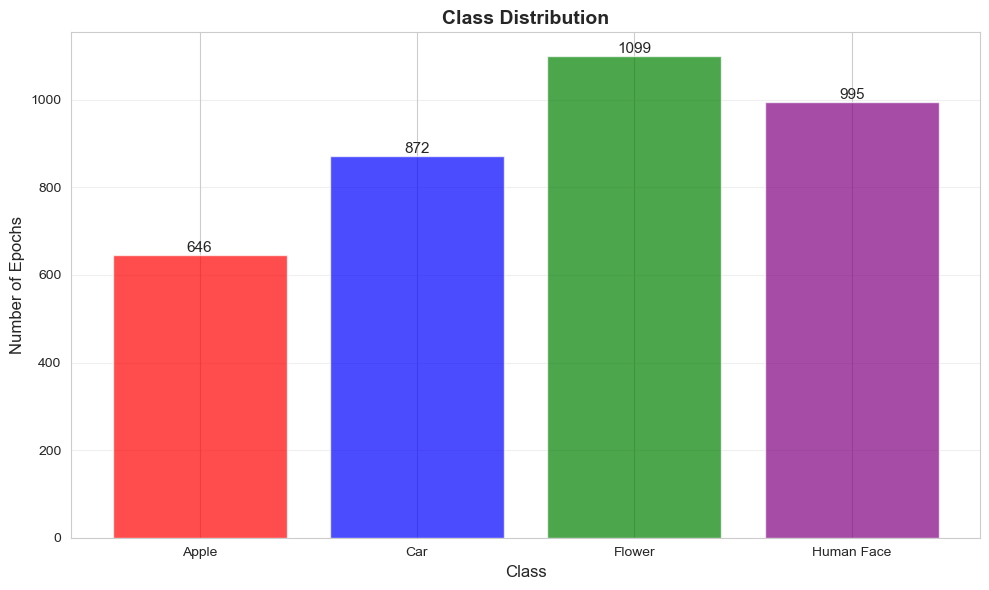

In [11]:
# Separate features (X) and labels (y)
# Remove metadata columns: Class, Phase, Subject
X = df_all.iloc[:, :-3].values  # All EEG features
y = df_all['Class'].values       # Class labels (1, 2, 3, 4)

print(f"Features shape: {X.shape}")
print(f"Labels shape: {y.shape}")
print(f"\nFeature dimensions: {X.shape[1]} features")
print(f"  - 14 channels × 128 timepoints = {14*128} features")

# Check for NaN or Inf values
print(f"\nNaN values: {np.isnan(X).sum()}")
print(f"Inf values: {np.isinf(X).sum()}")

# Visualize class distribution
plt.figure(figsize=(10, 6))
class_counts = pd.Series(y).value_counts().sort_index()
bars = plt.bar([class_map[i] for i in class_counts.index], class_counts.values, 
               color=['red', 'blue', 'green', 'purple'], alpha=0.7)
plt.xlabel('Class', fontsize=12)
plt.ylabel('Number of Epochs', fontsize=12)
plt.title('Class Distribution', fontsize=14, fontweight='bold')
plt.grid(axis='y', alpha=0.3)

# Add count labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}', ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

## 4. Setup Stratified 5-Fold Cross-Validation

In [12]:
# Initialize Stratified K-Fold
n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

# Storage for results
fold_results = {
    'accuracy': [],
    'f1_macro': [],
    'f1_weighted': [],
    'precision_macro': [],
    'recall_macro': [],
    'confusion_matrices': []
}

print(f"✅ Stratified {n_splits}-Fold Cross-Validation initialized")
print(f"Random state: 42 (reproducible results)")
print(f"\nData will be split into:")
print(f"  - Training: ~{100*(n_splits-1)/n_splits:.1f}% per fold")
print(f"  - Testing: ~{100/n_splits:.1f}% per fold")

✅ Stratified 5-Fold Cross-Validation initialized
Random state: 42 (reproducible results)

Data will be split into:
  - Training: ~80.0% per fold
  - Testing: ~20.0% per fold


In [13]:
# Create folder to save fold splits
import os
import json

FOLD_DIR = Path("trainfold")
FOLD_DIR.mkdir(exist_ok=True)

print(f"Saving fold splits to: {FOLD_DIR}/")
print("="*60)

# Split and save each fold
fold_info = []

for fold_num, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
    print(f"\nFold {fold_num}:")
    
    # Get train/test data
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    # Create fold directory
    fold_path = FOLD_DIR / f"fold_{fold_num}"
    fold_path.mkdir(exist_ok=True)
    
    # Save train data
    train_data = pd.DataFrame(X_train)
    train_data['Class'] = y_train
    train_file = fold_path / "train.csv"
    train_data.to_csv(train_file, index=False)
    
    # Save test data
    test_data = pd.DataFrame(X_test)
    test_data['Class'] = y_test
    test_file = fold_path / "test.csv"
    test_data.to_csv(test_file, index=False)
    
    # Collect fold statistics
    fold_stat = {
        'fold': fold_num,
        'train_samples': len(X_train),
        'test_samples': len(X_test),
        'train_class_dist': np.bincount(y_train).tolist(),
        'test_class_dist': np.bincount(y_test).tolist()
    }
    fold_info.append(fold_stat)
    
    print(f"  Train: {len(X_train)} samples → {train_file}")
    print(f"  Test:  {len(X_test)} samples → {test_file}")
    print(f"  Train class distribution: {np.bincount(y_train)}")
    print(f"  Test class distribution:  {np.bincount(y_test)}")

# Save fold info as JSON
info_file = FOLD_DIR / "fold_info.json"
with open(info_file, 'w') as f:
    json.dump(fold_info, f, indent=2)

print(f"\n{'='*60}")
print(f"✅ All {n_splits} folds saved successfully!")
print(f"✅ Fold information saved to: {info_file}")
print(f"{'='*60}")

Saving fold splits to: trainfold/

Fold 1:
  Train: 2889 samples → trainfold\fold_1\train.csv
  Test:  723 samples → trainfold\fold_1\test.csv
  Train class distribution: [  0 516 698 879 796]
  Test class distribution:  [  0 130 174 220 199]

Fold 2:
  Train: 2889 samples → trainfold\fold_1\train.csv
  Test:  723 samples → trainfold\fold_1\test.csv
  Train class distribution: [  0 516 698 879 796]
  Test class distribution:  [  0 130 174 220 199]

Fold 2:
  Train: 2889 samples → trainfold\fold_2\train.csv
  Test:  723 samples → trainfold\fold_2\test.csv
  Train class distribution: [  0 517 697 879 796]
  Test class distribution:  [  0 129 175 220 199]

Fold 3:
  Train: 2889 samples → trainfold\fold_2\train.csv
  Test:  723 samples → trainfold\fold_2\test.csv
  Train class distribution: [  0 517 697 879 796]
  Test class distribution:  [  0 129 175 220 199]

Fold 3:
  Train: 2890 samples → trainfold\fold_3\train.csv
  Test:  722 samples → trainfold\fold_3\test.csv
  Train class distrib

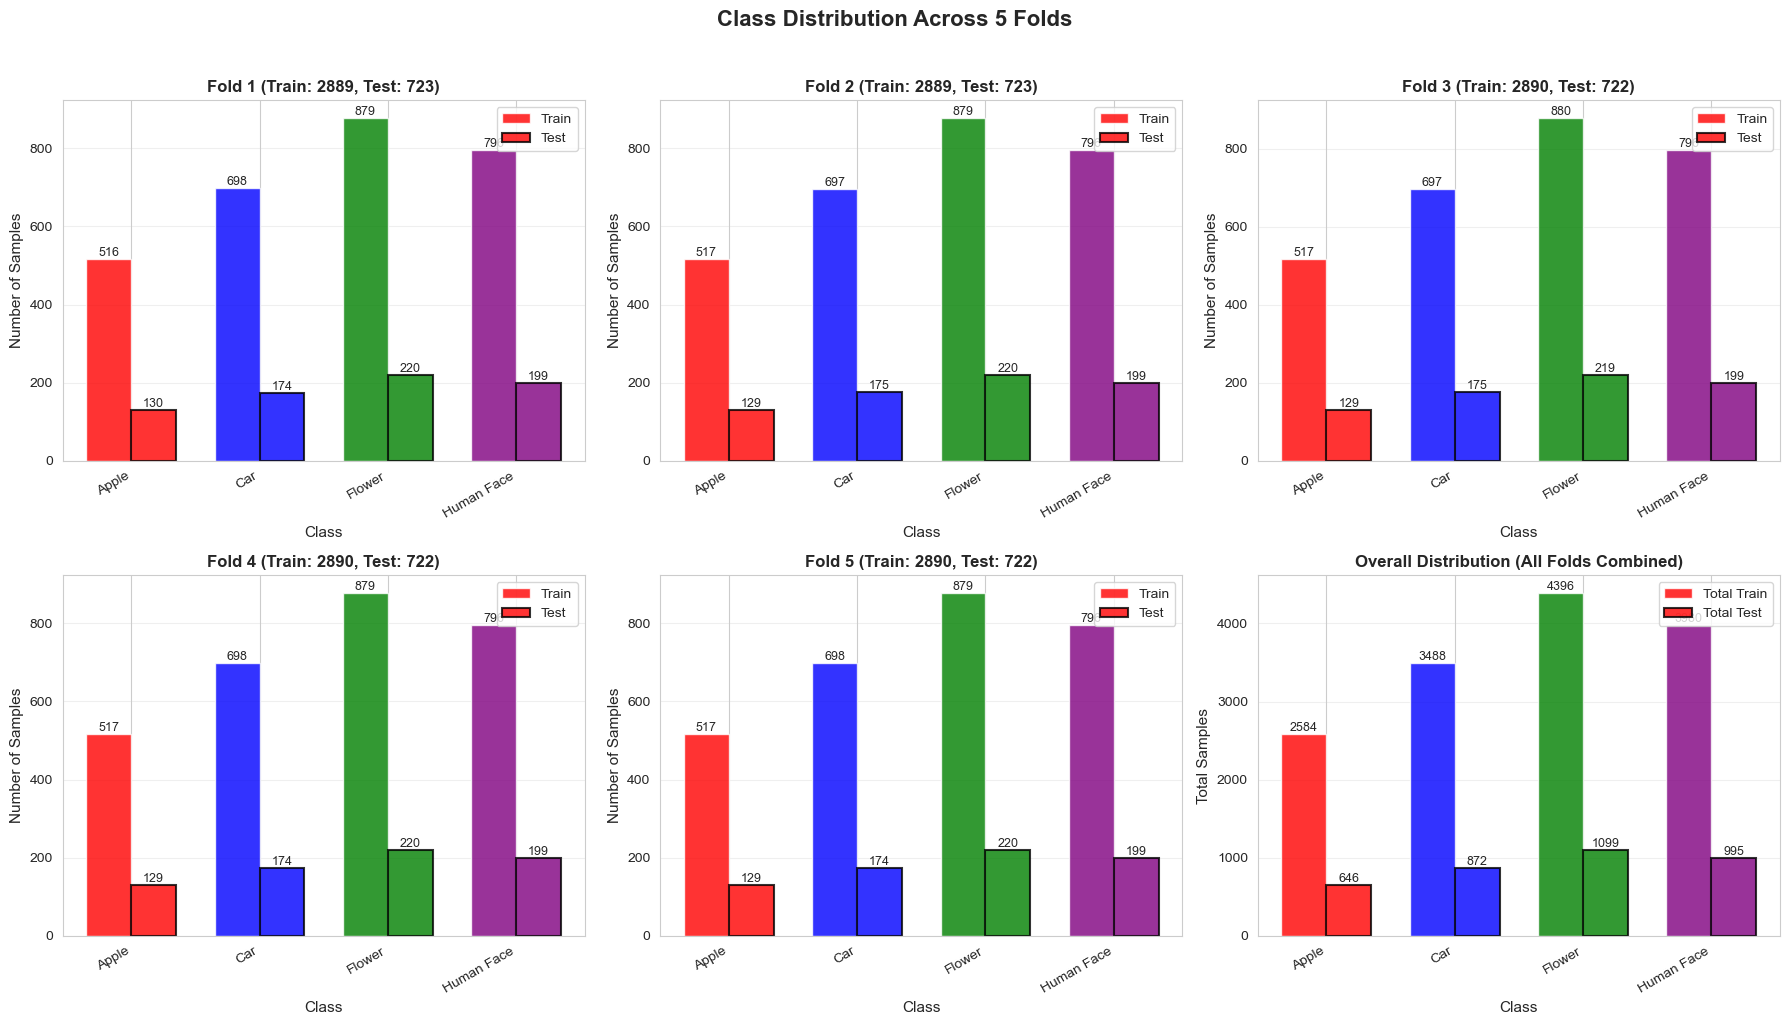


CLASS BALANCE SUMMARY ACROSS FOLDS

Fold 1:
  Train class percentages:
    Apple: 516 (17.9%)
    Car: 698 (24.2%)
    Flower: 879 (30.4%)
    Human Face: 796 (27.6%)
  Test class percentages:
    Apple: 130 (18.0%)
    Car: 174 (24.1%)
    Flower: 220 (30.4%)
    Human Face: 199 (27.5%)

Fold 2:
  Train class percentages:
    Apple: 517 (17.9%)
    Car: 697 (24.1%)
    Flower: 879 (30.4%)
    Human Face: 796 (27.6%)
  Test class percentages:
    Apple: 129 (17.8%)
    Car: 175 (24.2%)
    Flower: 220 (30.4%)
    Human Face: 199 (27.5%)

Fold 3:
  Train class percentages:
    Apple: 517 (17.9%)
    Car: 697 (24.1%)
    Flower: 880 (30.4%)
    Human Face: 796 (27.5%)
  Test class percentages:
    Apple: 129 (17.9%)
    Car: 175 (24.2%)
    Flower: 219 (30.3%)
    Human Face: 199 (27.6%)

Fold 4:
  Train class percentages:
    Apple: 517 (17.9%)
    Car: 698 (24.2%)
    Flower: 879 (30.4%)
    Human Face: 796 (27.5%)
  Test class percentages:
    Apple: 129 (17.9%)
    Car: 174 (24.1%)


In [14]:
# Visualize class distribution across folds
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Class Distribution Across 5 Folds', fontsize=16, fontweight='bold', y=1.02)

# Flatten axes for easier iteration
axes = axes.flatten()

# Class colors
colors = ['red', 'blue', 'green', 'purple']

# Plot each fold
for fold_num, fold_stat in enumerate(fold_info, 1):
    ax = axes[fold_num - 1]
    
    # Prepare data for grouped bar chart
    train_dist = fold_stat['train_class_dist'][1:]  # Skip index 0 (no class 0)
    test_dist = fold_stat['test_class_dist'][1:]
    
    x = np.arange(len(class_names))
    width = 0.35
    
    # Create bars
    bars1 = ax.bar(x - width/2, train_dist, width, label='Train', alpha=0.8, color=colors)
    bars2 = ax.bar(x + width/2, test_dist, width, label='Test', alpha=0.8, 
                   color=colors, edgecolor='black', linewidth=1.5)
    
    # Customize
    ax.set_xlabel('Class', fontsize=11)
    ax.set_ylabel('Number of Samples', fontsize=11)
    ax.set_title(f'Fold {fold_num} (Train: {fold_stat["train_samples"]}, Test: {fold_stat["test_samples"]})', 
                 fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(class_names, rotation=30, ha='right')
    ax.legend(loc='upper right')
    ax.grid(axis='y', alpha=0.3)
    
    # Add value labels on bars
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{int(height)}', ha='center', va='bottom', fontsize=9)

# Summary plot (last subplot)
ax = axes[5]
total_train = [sum([f['train_class_dist'][i+1] for f in fold_info]) for i in range(4)]
total_test = [sum([f['test_class_dist'][i+1] for f in fold_info]) for i in range(4)]

x = np.arange(len(class_names))
bars1 = ax.bar(x - width/2, total_train, width, label='Total Train', alpha=0.8, color=colors)
bars2 = ax.bar(x + width/2, total_test, width, label='Total Test', alpha=0.8, 
               color=colors, edgecolor='black', linewidth=1.5)

ax.set_xlabel('Class', fontsize=11)
ax.set_ylabel('Total Samples', fontsize=11)
ax.set_title('Overall Distribution (All Folds Combined)', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=30, ha='right')
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.3)

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
               f'{int(height)}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

# Print summary statistics
print("\n" + "="*60)
print("CLASS BALANCE SUMMARY ACROSS FOLDS")
print("="*60)

for fold_num, fold_stat in enumerate(fold_info, 1):
    print(f"\nFold {fold_num}:")
    print(f"  Train class percentages:")
    train_total = sum(fold_stat['train_class_dist'][1:])
    for i, class_name in enumerate(class_names):
        count = fold_stat['train_class_dist'][i+1]
        pct = 100 * count / train_total
        print(f"    {class_name}: {count} ({pct:.1f}%)")
    
    print(f"  Test class percentages:")
    test_total = sum(fold_stat['test_class_dist'][1:])
    for i, class_name in enumerate(class_names):
        count = fold_stat['test_class_dist'][i+1]
        pct = 100 * count / test_total
        print(f"    {class_name}: {count} ({pct:.1f}%)")

print("\n" + "="*60)

## 5. Train SVM with RBF Kernel (5-Fold CV)

In [8]:
print("="*60)
print(f"Training SVM with RBF Kernel - 5-Fold Cross-Validation ({'GPU' if USE_GPU else 'CPU'})")
print("="*60)

fold_num = 1

for train_idx, test_idx in skf.split(X, y):
    print(f"\n{'='*60}")
    print(f"FOLD {fold_num}/{n_splits}")
    print(f"{'='*60}")
    
    # Split data
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    print(f"Training samples: {len(X_train)}")
    print(f"Testing samples: {len(X_test)}")
    print(f"Train class distribution: {np.bincount(y_train)}")
    print(f"Test class distribution: {np.bincount(y_test)}")
    
    # Standardize features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Train SVM with RBF kernel
    if USE_GPU and THUNDERSVM_AVAILABLE:
        # Option 1: ThunderSVM (fastest for large datasets)
        print(f"\nTraining ThunderSVM (RBF kernel) on GPU...")
        svm_model = ThunderSVC(kernel='rbf', C=1.0, gamma='scale', gpu_id=0)
        svm_model.fit(X_train_scaled, y_train)
        y_pred = svm_model.predict(X_test_scaled)
        y_test_cpu = y_test
        
    elif USE_GPU:
        # Option 2: Move data to GPU with PyTorch, train on CPU but benefit from GPU memory
        print(f"\nTraining SVM (RBF kernel) with GPU-accelerated data transfer...")
        import torch
        
        # Transfer to GPU
        X_train_gpu = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
        X_test_gpu = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
        
        # Train on CPU (sklearn SVM is CPU-only, but we prepare data on GPU)
        svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
        
        # Transfer back to CPU for training (sklearn requires CPU)
        X_train_cpu = X_train_gpu.cpu().numpy()
        X_test_cpu = X_test_gpu.cpu().numpy()
        
        svm_model.fit(X_train_cpu, y_train)
        y_pred = svm_model.predict(X_test_cpu)
        y_test_cpu = y_test
        
        # Clear GPU memory
        del X_train_gpu, X_test_gpu
        torch.cuda.empty_cache()
        
    else:
        # Option 3: Pure CPU training
        print(f"\nTraining SVM (RBF kernel) on CPU...")
        svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
        svm_model.fit(X_train_scaled, y_train)
        y_pred = svm_model.predict(X_test_scaled)
        y_test_cpu = y_test
    
    # Calculate metrics (on CPU)
    accuracy = accuracy_score(y_test_cpu, y_pred)
    f1_macro = f1_score(y_test_cpu, y_pred, average='macro')
    f1_weighted = f1_score(y_test_cpu, y_pred, average='weighted')
    precision = precision_score(y_test_cpu, y_pred, average='macro')
    recall = recall_score(y_test_cpu, y_pred, average='macro')
    cm = confusion_matrix(y_test_cpu, y_pred)
    
    # Store results
    fold_results['accuracy'].append(accuracy)
    fold_results['f1_macro'].append(f1_macro)
    fold_results['f1_weighted'].append(f1_weighted)
    fold_results['precision_macro'].append(precision)
    fold_results['recall_macro'].append(recall)
    fold_results['confusion_matrices'].append(cm)
    
    # Print results
    print(f"\n✅ Fold {fold_num} Results:")
    print(f"  Accuracy: {accuracy:.4f}")
    print(f"  F1-Score (Macro): {f1_macro:.4f}")
    print(f"  F1-Score (Weighted): {f1_weighted:.4f}")
    print(f"  Precision (Macro): {precision:.4f}")
    print(f"  Recall (Macro): {recall:.4f}")
    
    fold_num += 1

print(f"\n{'='*60}")
print("CROSS-VALIDATION COMPLETED")
print(f"{'='*60}")


Training SVM with RBF Kernel - 5-Fold Cross-Validation (GPU)

FOLD 1/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 516 698 879 796]
Test class distribution: [  0 130 174 220 199]

Training SVM (RBF kernel) with GPU-accelerated data transfer...

✅ Fold 1 Results:
  Accuracy: 0.4329
  F1-Score (Macro): 0.3990
  F1-Score (Weighted): 0.4162
  Precision (Macro): 0.4344
  Recall (Macro): 0.4045

FOLD 2/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 517 697 879 796]
Test class distribution: [  0 129 175 220 199]

Training SVM (RBF kernel) with GPU-accelerated data transfer...

✅ Fold 2 Results:
  Accuracy: 0.4163
  F1-Score (Macro): 0.3677
  F1-Score (Weighted): 0.3900
  Precision (Macro): 0.4338
  Recall (Macro): 0.3803

FOLD 3/5
Training samples: 2890
Testing samples: 722
Train class distribution: [  0 517 697 880 796]
Test class distribution: [  0 129 175 219 199]

Training SVM (RBF kernel) with GPU-accelerated data transfer...



## 6. Train Random Forest Classifier (5-Fold CV)

In [15]:
from sklearn.ensemble import RandomForestClassifier

# Storage for Random Forest results
rf_fold_results = {
    'accuracy': [],
    'f1_macro': [],
    'f1_weighted': [],
    'precision_macro': [],
    'recall_macro': [],
    'confusion_matrices': []
}

print("="*60)
print("Training Random Forest Classifier - 5-Fold Cross-Validation")
print("="*60)

fold_num = 1

for train_idx, test_idx in skf.split(X, y):
    print(f"\n{'='*60}")
    print(f"FOLD {fold_num}/{n_splits}")
    print(f"{'='*60}")
    
    # Split data
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    print(f"Training samples: {len(X_train)}")
    print(f"Testing samples: {len(X_test)}")
    print(f"Train class distribution: {np.bincount(y_train)}")
    print(f"Test class distribution: {np.bincount(y_test)}")
    
    # Standardize features (optional for RF but good practice)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Train Random Forest
    print(f"\nTraining Random Forest (n_estimators=100)...")
    rf_model = RandomForestClassifier(
        n_estimators=100,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1,  # Use all CPU cores
        verbose=0
    )
    
    rf_model.fit(X_train_scaled, y_train)
    y_pred = rf_model.predict(X_test_scaled)
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='macro')
    recall = recall_score(y_test, y_pred, average='macro')
    cm = confusion_matrix(y_test, y_pred)
    
    # Store results
    rf_fold_results['accuracy'].append(accuracy)
    rf_fold_results['f1_macro'].append(f1_macro)
    rf_fold_results['f1_weighted'].append(f1_weighted)
    rf_fold_results['precision_macro'].append(precision)
    rf_fold_results['recall_macro'].append(recall)
    rf_fold_results['confusion_matrices'].append(cm)
    
    # Print results
    print(f"\n✅ Fold {fold_num} Results:")
    print(f"  Accuracy: {accuracy:.4f}")
    print(f"  F1-Score (Macro): {f1_macro:.4f}")
    print(f"  F1-Score (Weighted): {f1_weighted:.4f}")
    print(f"  Precision (Macro): {precision:.4f}")
    print(f"  Recall (Macro): {recall:.4f}")
    
    fold_num += 1

print(f"\n{'='*60}")
print("RANDOM FOREST CROSS-VALIDATION COMPLETED")
print(f"{'='*60}")

Training Random Forest Classifier - 5-Fold Cross-Validation

FOLD 1/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 516 698 879 796]
Test class distribution: [  0 130 174 220 199]

Training Random Forest (n_estimators=100)...

✅ Fold 1 Results:
  Accuracy: 0.4689
  F1-Score (Macro): 0.4432
  F1-Score (Weighted): 0.4576
  Precision (Macro): 0.4703
  Recall (Macro): 0.4426

FOLD 2/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 517 697 879 796]
Test class distribution: [  0 129 175 220 199]

Training Random Forest (n_estimators=100)...

✅ Fold 1 Results:
  Accuracy: 0.4689
  F1-Score (Macro): 0.4432
  F1-Score (Weighted): 0.4576
  Precision (Macro): 0.4703
  Recall (Macro): 0.4426

FOLD 2/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 517 697 879 796]
Test class distribution: [  0 129 175 220 199]

Training Random Forest (n_estimators=100)...

✅ Fold 2 Results:
  Accuracy: 0.4149
  F1-Score (Macro): 0

## 7. Random Forest Performance Summary


RANDOM FOREST 5-FOLD CROSS-VALIDATION SUMMARY
             Metric     Mean      Std
           Accuracy 0.445739 0.018128
   F1-Score (Macro) 0.412948 0.018054
F1-Score (Weighted) 0.429706 0.018338
  Precision (Macro) 0.455309 0.013529
     Recall (Macro) 0.416002 0.017367


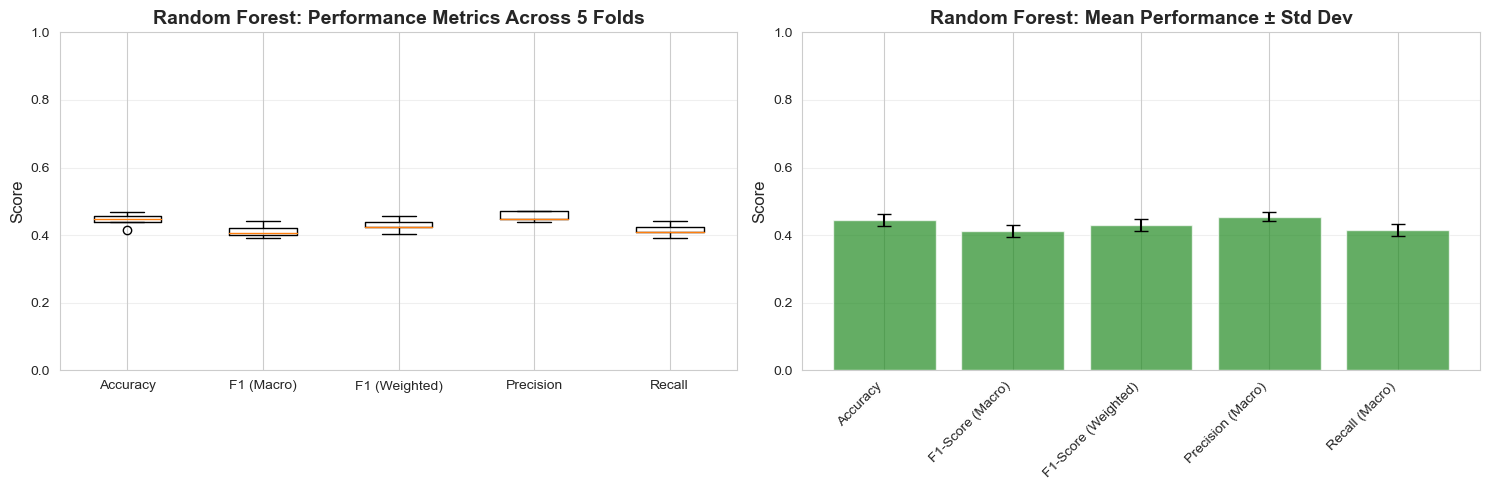

In [16]:
# Calculate mean and std for Random Forest metrics
rf_results_summary = {
    'Metric': ['Accuracy', 'F1-Score (Macro)', 'F1-Score (Weighted)', 'Precision (Macro)', 'Recall (Macro)'],
    'Mean': [
        np.mean(rf_fold_results['accuracy']),
        np.mean(rf_fold_results['f1_macro']),
        np.mean(rf_fold_results['f1_weighted']),
        np.mean(rf_fold_results['precision_macro']),
        np.mean(rf_fold_results['recall_macro'])
    ],
    'Std': [
        np.std(rf_fold_results['accuracy']),
        np.std(rf_fold_results['f1_macro']),
        np.std(rf_fold_results['f1_weighted']),
        np.std(rf_fold_results['precision_macro']),
        np.std(rf_fold_results['recall_macro'])
    ]
}

df_rf_summary = pd.DataFrame(rf_results_summary)

print("\n" + "="*60)
print("RANDOM FOREST 5-FOLD CROSS-VALIDATION SUMMARY")
print("="*60)
print(df_rf_summary.to_string(index=False))
print("="*60)

# Visualize Random Forest results
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Box plot of metrics across folds
rf_metrics_data = pd.DataFrame({
    'Accuracy': rf_fold_results['accuracy'],
    'F1 (Macro)': rf_fold_results['f1_macro'],
    'F1 (Weighted)': rf_fold_results['f1_weighted'],
    'Precision': rf_fold_results['precision_macro'],
    'Recall': rf_fold_results['recall_macro']
})

axes[0].boxplot(rf_metrics_data.values, labels=rf_metrics_data.columns)
axes[0].set_ylabel('Score', fontsize=12)
axes[0].set_title('Random Forest: Performance Metrics Across 5 Folds', fontsize=14, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim([0, 1])

# Plot 2: Bar plot with error bars
x_pos = np.arange(len(df_rf_summary))
axes[1].bar(x_pos, df_rf_summary['Mean'], yerr=df_rf_summary['Std'], 
            capsize=5, alpha=0.7, color='forestgreen')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(df_rf_summary['Metric'], rotation=45, ha='right')
axes[1].set_ylabel('Score', fontsize=12)
axes[1].set_title('Random Forest: Mean Performance ± Std Dev', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.show()

## 8. Random Forest Confusion Matrix

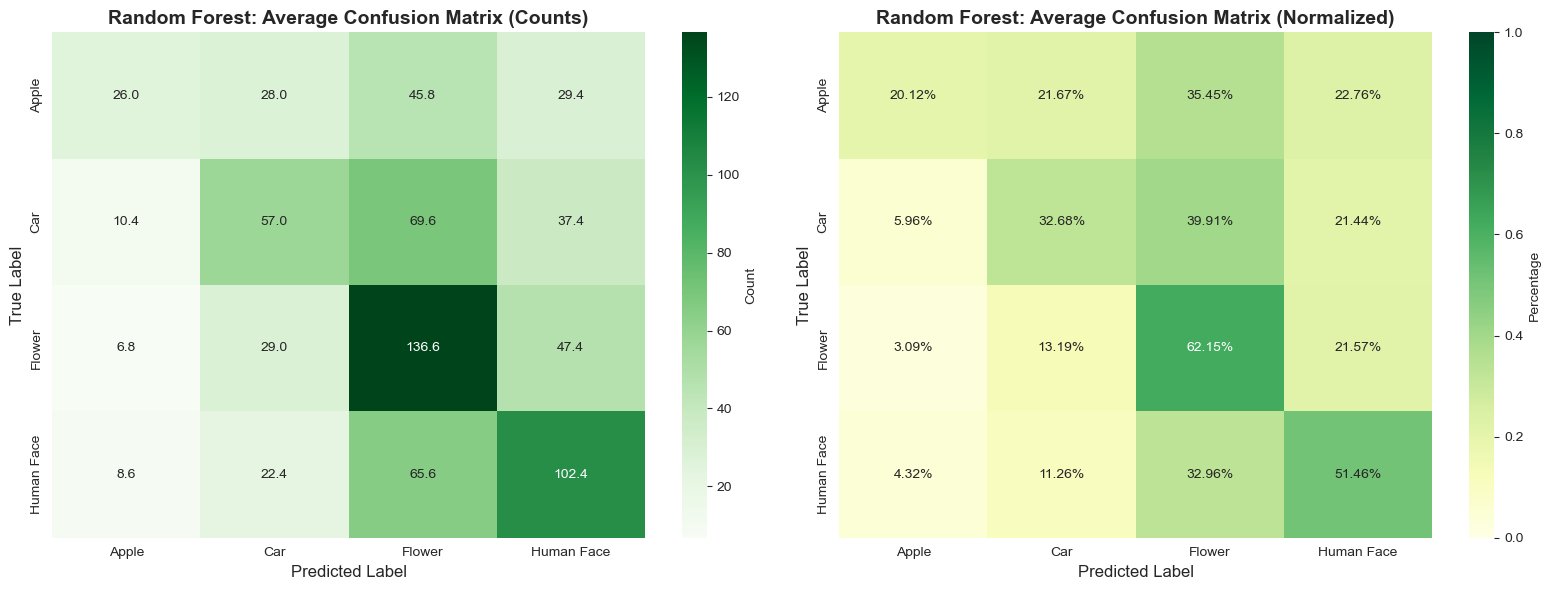


Random Forest Per-Class Accuracy:
  Apple: 20.12%
  Car: 32.68%
  Flower: 62.15%
  Human Face: 51.46%


In [17]:
# Average confusion matrix for Random Forest across all folds
rf_avg_cm = np.mean(rf_fold_results['confusion_matrices'], axis=0)
rf_avg_cm_normalized = rf_avg_cm / rf_avg_cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Raw counts
sns.heatmap(rf_avg_cm, annot=True, fmt='.1f', cmap='Greens', 
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[0], cbar_kws={'label': 'Count'})
axes[0].set_title('Random Forest: Average Confusion Matrix (Counts)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Label', fontsize=12)
axes[0].set_xlabel('Predicted Label', fontsize=12)

# Plot 2: Normalized (percentages)
sns.heatmap(rf_avg_cm_normalized, annot=True, fmt='.2%', cmap='YlGn', 
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[1], cbar_kws={'label': 'Percentage'}, vmin=0, vmax=1)
axes[1].set_title('Random Forest: Average Confusion Matrix (Normalized)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=12)
axes[1].set_xlabel('Predicted Label', fontsize=12)

plt.tight_layout()
plt.show()

# Per-class accuracy for Random Forest
print("\nRandom Forest Per-Class Accuracy:")
for i, class_name in enumerate(class_names):
    class_acc = rf_avg_cm_normalized[i, i]
    print(f"  {class_name}: {class_acc:.2%}")

## 9. Train Decision Tree Classifier (5-Fold CV)

In [18]:
from sklearn.tree import DecisionTreeClassifier

# Storage for Decision Tree results
dt_fold_results = {
    'accuracy': [],
    'f1_macro': [],
    'f1_weighted': [],
    'precision_macro': [],
    'recall_macro': [],
    'confusion_matrices': []
}

print("="*60)
print("Training Decision Tree Classifier - 5-Fold Cross-Validation")
print("="*60)

fold_num = 1

for train_idx, test_idx in skf.split(X, y):
    print(f"\n{'='*60}")
    print(f"FOLD {fold_num}/{n_splits}")
    print(f"{'='*60}")
    
    # Split data
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    print(f"Training samples: {len(X_train)}")
    print(f"Testing samples: {len(X_test)}")
    print(f"Train class distribution: {np.bincount(y_train)}")
    print(f"Test class distribution: {np.bincount(y_test)}")
    
    # Standardize features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Train Decision Tree
    print(f"\nTraining Decision Tree...")
    dt_model = DecisionTreeClassifier(
        criterion='gini',
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42
    )
    
    dt_model.fit(X_train_scaled, y_train)
    y_pred = dt_model.predict(X_test_scaled)
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='macro')
    recall = recall_score(y_test, y_pred, average='macro')
    cm = confusion_matrix(y_test, y_pred)
    
    # Store results
    dt_fold_results['accuracy'].append(accuracy)
    dt_fold_results['f1_macro'].append(f1_macro)
    dt_fold_results['f1_weighted'].append(f1_weighted)
    dt_fold_results['precision_macro'].append(precision)
    dt_fold_results['recall_macro'].append(recall)
    dt_fold_results['confusion_matrices'].append(cm)
    
    # Print results
    print(f"\n✅ Fold {fold_num} Results:")
    print(f"  Accuracy: {accuracy:.4f}")
    print(f"  F1-Score (Macro): {f1_macro:.4f}")
    print(f"  F1-Score (Weighted): {f1_weighted:.4f}")
    print(f"  Precision (Macro): {precision:.4f}")
    print(f"  Recall (Macro): {recall:.4f}")
    
    fold_num += 1

print(f"\n{'='*60}")
print("DECISION TREE CROSS-VALIDATION COMPLETED")
print(f"{'='*60}")

Training Decision Tree Classifier - 5-Fold Cross-Validation

FOLD 1/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 516 698 879 796]
Test class distribution: [  0 130 174 220 199]

Training Decision Tree...

✅ Fold 1 Results:
  Accuracy: 0.3181
  F1-Score (Macro): 0.3108
  F1-Score (Weighted): 0.3177
  Precision (Macro): 0.3111
  Recall (Macro): 0.3109

FOLD 2/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 517 697 879 796]
Test class distribution: [  0 129 175 220 199]

Training Decision Tree...

✅ Fold 1 Results:
  Accuracy: 0.3181
  F1-Score (Macro): 0.3108
  F1-Score (Weighted): 0.3177
  Precision (Macro): 0.3111
  Recall (Macro): 0.3109

FOLD 2/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 517 697 879 796]
Test class distribution: [  0 129 175 220 199]

Training Decision Tree...

✅ Fold 2 Results:
  Accuracy: 0.2849
  F1-Score (Macro): 0.2773
  F1-Score (Weighted): 0.2849
  Precision (Macro): 

## 10. Train Logistic Regression (5-Fold CV)

In [19]:
from sklearn.linear_model import LogisticRegression

# Storage for Logistic Regression results
lr_fold_results = {
    'accuracy': [],
    'f1_macro': [],
    'f1_weighted': [],
    'precision_macro': [],
    'recall_macro': [],
    'confusion_matrices': []
}

print("="*60)
print("Training Logistic Regression - 5-Fold Cross-Validation")
print("="*60)

fold_num = 1

for train_idx, test_idx in skf.split(X, y):
    print(f"\n{'='*60}")
    print(f"FOLD {fold_num}/{n_splits}")
    print(f"{'='*60}")
    
    # Split data
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    print(f"Training samples: {len(X_train)}")
    print(f"Testing samples: {len(X_test)}")
    print(f"Train class distribution: {np.bincount(y_train)}")
    print(f"Test class distribution: {np.bincount(y_test)}")
    
    # Standardize features (important for LR)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Train Logistic Regression
    print(f"\nTraining Logistic Regression (multi_class='multinomial')...")
    lr_model = LogisticRegression(
        multi_class='multinomial',
        solver='lbfgs',
        max_iter=1000,
        random_state=42,
        n_jobs=-1
    )
    
    lr_model.fit(X_train_scaled, y_train)
    y_pred = lr_model.predict(X_test_scaled)
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='macro')
    recall = recall_score(y_test, y_pred, average='macro')
    cm = confusion_matrix(y_test, y_pred)
    
    # Store results
    lr_fold_results['accuracy'].append(accuracy)
    lr_fold_results['f1_macro'].append(f1_macro)
    lr_fold_results['f1_weighted'].append(f1_weighted)
    lr_fold_results['precision_macro'].append(precision)
    lr_fold_results['recall_macro'].append(recall)
    lr_fold_results['confusion_matrices'].append(cm)
    
    # Print results
    print(f"\n✅ Fold {fold_num} Results:")
    print(f"  Accuracy: {accuracy:.4f}")
    print(f"  F1-Score (Macro): {f1_macro:.4f}")
    print(f"  F1-Score (Weighted): {f1_weighted:.4f}")
    print(f"  Precision (Macro): {precision:.4f}")
    print(f"  Recall (Macro): {recall:.4f}")
    
    fold_num += 1

print(f"\n{'='*60}")
print("LOGISTIC REGRESSION CROSS-VALIDATION COMPLETED")
print(f"{'='*60}")

Training Logistic Regression - 5-Fold Cross-Validation

FOLD 1/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 516 698 879 796]
Test class distribution: [  0 130 174 220 199]

Training Logistic Regression (multi_class='multinomial')...

✅ Fold 1 Results:
  Accuracy: 0.2559
  F1-Score (Macro): 0.2510
  F1-Score (Weighted): 0.2568
  Precision (Macro): 0.2522
  Recall (Macro): 0.2509

FOLD 2/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 517 697 879 796]
Test class distribution: [  0 129 175 220 199]

Training Logistic Regression (multi_class='multinomial')...

✅ Fold 2 Results:
  Accuracy: 0.2573
  F1-Score (Macro): 0.2508
  F1-Score (Weighted): 0.2568
  Precision (Macro): 0.2505
  Recall (Macro): 0.2516

FOLD 3/5
Training samples: 2890
Testing samples: 722
Train class distribution: [  0 517 697 880 796]
Test class distribution: [  0 129 175 219 199]

Training Logistic Regression (multi_class='multinomial')...

✅ Fold 3 Results:


## 11. Train XGBoost Classifier (5-Fold CV)

In [24]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
import numpy as np

# 1) Encode y về 0..K-1 để nhất quán với mọi model
le = LabelEncoder()
y_enc = le.fit_transform(y)   # dùng y_enc cho mọi thứ: split, fit, predict

# 2) Chuẩn bị lưu kết quả
xgb_fold_results = {
    'accuracy': [],
    'f1_macro': [],
    'f1_weighted': [],
    'precision_macro': [],
    'recall_macro': [],
    'confusion_matrices': []
}

print("="*60)
print("Training XGBoost Classifier - Stratified K-Fold")
print("="*60)

# Lấy số folds từ skf (đã tạo ở trên), hoặc đặt n_splits = 5 nếu bạn dùng biến riêng
try:
    n_splits = skf.get_n_splits(X, y_enc)
except Exception:
    n_splits = 5

fold_num = 1
n_classes = len(le.classes_)

for train_idx, test_idx in skf.split(X, y_enc):
    print(f"\n{'='*60}")
    print(f"FOLD {fold_num}/{n_splits}")
    print(f"{'='*60}")

    # 3) Tách tập
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y_enc[train_idx], y_enc[test_idx]

    # In phân bố lớp (bảo đảm chiều dài bằng số lớp)
    train_counts = np.bincount(y_train, minlength=n_classes)
    test_counts  = np.bincount(y_test,  minlength=n_classes)

    print(f"Training samples: {len(X_train)}")
    print(f"Testing samples:  {len(X_test)}")
    print(f"Train class distribution: {train_counts}")
    print(f"Test  class distribution: {test_counts}")

    # 4) (Tuỳ chọn) Chuẩn hoá — XGBoost không bắt buộc, nhưng để giữ đúng code cũ
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled  = scaler.transform(X_test)

    # 5) Khởi tạo model MỚI cho mỗi fold (tránh tái dùng model đã fit trước)
    from xgboost import XGBClassifier
    print("\nTraining XGBoost...")
    xgb_model = XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        eval_metric='mlogloss',   # đa lớp
        # objective='multi:softprob', # không bắt buộc vì XGBClassifier tự suy ra từ y
        # num_class=n_classes,        # không cần, XGBClassifier tự xét
    )

    xgb_model.fit(X_train_scaled, y_train)
    y_pred = xgb_model.predict(X_test_scaled)

    # 6) Tính metric
    accuracy = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='macro')
    recall = recall_score(y_test, y_pred, average='macro')
    cm = confusion_matrix(y_test, y_pred, labels=np.arange(n_classes))

    # 7) Lưu kết quả
    xgb_fold_results['accuracy'].append(accuracy)
    xgb_fold_results['f1_macro'].append(f1_macro)
    xgb_fold_results['f1_weighted'].append(f1_weighted)
    xgb_fold_results['precision_macro'].append(precision)
    xgb_fold_results['recall_macro'].append(recall)
    xgb_fold_results['confusion_matrices'].append(cm)

    # 8) In kết quả fold
    print(f"\n✅ Fold {fold_num} Results:")
    print(f"  Accuracy: {accuracy:.4f}")
    print(f"  F1-Score (Macro): {f1_macro:.4f}")
    print(f"  F1-Score (Weighted): {f1_weighted:.4f}")
    print(f"  Precision (Macro): {precision:.4f}")
    print(f"  Recall (Macro): {recall:.4f}")

    fold_num += 1

print(f"\n{'='*60}")
print("XGBOOST CROSS-VALIDATION COMPLETED")
print(f"{'='*60}")


Training XGBoost Classifier - Stratified K-Fold

FOLD 1/5
Training samples: 2889
Testing samples:  723
Train class distribution: [516 698 879 796]
Test  class distribution: [130 174 220 199]

Training XGBoost...

✅ Fold 1 Results:
  Accuracy: 0.4440
  F1-Score (Macro): 0.4260
  F1-Score (Weighted): 0.4380
  Precision (Macro): 0.4383
  Recall (Macro): 0.4245

FOLD 2/5
Training samples: 2889
Testing samples:  723
Train class distribution: [517 697 879 796]
Test  class distribution: [129 175 220 199]

Training XGBoost...

✅ Fold 2 Results:
  Accuracy: 0.4080
  F1-Score (Macro): 0.3790
  F1-Score (Weighted): 0.3946
  Precision (Macro): 0.4080
  Recall (Macro): 0.3814

FOLD 3/5
Training samples: 2890
Testing samples:  722
Train class distribution: [517 697 880 796]
Test  class distribution: [129 175 219 199]

Training XGBoost...

✅ Fold 3 Results:
  Accuracy: 0.4571
  F1-Score (Macro): 0.4361
  F1-Score (Weighted): 0.4476
  Precision (Macro): 0.4690
  Recall (Macro): 0.4336

FOLD 4/5
Traini

## 12. Train CatBoost Classifier (5-Fold CV)

In [22]:
# Check if CatBoost is installed, if not install it
try:
    import catboost
    print("✅ CatBoost already installed")
except ImportError:
    print("⚠️  CatBoost not found, installing...")
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "catboost"])
    import catboost
    print("✅ CatBoost installed successfully")

from catboost import CatBoostClassifier

# Storage for CatBoost results
cb_fold_results = {
    'accuracy': [],
    'f1_macro': [],
    'f1_weighted': [],
    'precision_macro': [],
    'recall_macro': [],
    'confusion_matrices': []
}

print("="*60)
print("Training CatBoost Classifier - 5-Fold Cross-Validation")
print("="*60)

fold_num = 1

for train_idx, test_idx in skf.split(X, y):
    print(f"\n{'='*60}")
    print(f"FOLD {fold_num}/{n_splits}")
    print(f"{'='*60}")
    
    # Split data
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    print(f"Training samples: {len(X_train)}")
    print(f"Testing samples: {len(X_test)}")
    print(f"Train class distribution: {np.bincount(y_train)}")
    print(f"Test class distribution: {np.bincount(y_test)}")
    
    # Standardize features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Train CatBoost
    print(f"\nTraining CatBoost...")
    cb_model = CatBoostClassifier(
        iterations=100,
        depth=6,
        learning_rate=0.1,
        random_state=42,
        verbose=0,
        thread_count=-1
    )
    
    cb_model.fit(X_train_scaled, y_train)
    y_pred = cb_model.predict(X_test_scaled)
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='macro')
    recall = recall_score(y_test, y_pred, average='macro')
    cm = confusion_matrix(y_test, y_pred)
    
    # Store results
    cb_fold_results['accuracy'].append(accuracy)
    cb_fold_results['f1_macro'].append(f1_macro)
    cb_fold_results['f1_weighted'].append(f1_weighted)
    cb_fold_results['precision_macro'].append(precision)
    cb_fold_results['recall_macro'].append(recall)
    cb_fold_results['confusion_matrices'].append(cm)
    
    # Print results
    print(f"\n✅ Fold {fold_num} Results:")
    print(f"  Accuracy: {accuracy:.4f}")
    print(f"  F1-Score (Macro): {f1_macro:.4f}")
    print(f"  F1-Score (Weighted): {f1_weighted:.4f}")
    print(f"  Precision (Macro): {precision:.4f}")
    print(f"  Recall (Macro): {recall:.4f}")
    
    fold_num += 1

print(f"\n{'='*60}")
print("CATBOOST CROSS-VALIDATION COMPLETED")
print(f"{'='*60}")

✅ CatBoost already installed
Training CatBoost Classifier - 5-Fold Cross-Validation

FOLD 1/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 516 698 879 796]
Test class distribution: [  0 130 174 220 199]

Training CatBoost...

✅ Fold 1 Results:
  Accuracy: 0.3817
  F1-Score (Macro): 0.3439
  F1-Score (Weighted): 0.3623
  Precision (Macro): 0.3724
  Recall (Macro): 0.3521

FOLD 2/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 517 697 879 796]
Test class distribution: [  0 129 175 220 199]

Training CatBoost...

✅ Fold 1 Results:
  Accuracy: 0.3817
  F1-Score (Macro): 0.3439
  F1-Score (Weighted): 0.3623
  Precision (Macro): 0.3724
  Recall (Macro): 0.3521

FOLD 2/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 517 697 879 796]
Test class distribution: [  0 129 175 220 199]

Training CatBoost...

✅ Fold 2 Results:
  Accuracy: 0.3790
  F1-Score (Macro): 0.3501
  F1-Score (Weighted): 0.3636
  Precision 

## 13. Train AdaBoost Classifier (5-Fold CV)

In [23]:
from sklearn.ensemble import AdaBoostClassifier

# Storage for AdaBoost results
ada_fold_results = {
    'accuracy': [],
    'f1_macro': [],
    'f1_weighted': [],
    'precision_macro': [],
    'recall_macro': [],
    'confusion_matrices': []
}

print("="*60)
print("Training AdaBoost Classifier - 5-Fold Cross-Validation")
print("="*60)

fold_num = 1

for train_idx, test_idx in skf.split(X, y):
    print(f"\n{'='*60}")
    print(f"FOLD {fold_num}/{n_splits}")
    print(f"{'='*60}")
    
    # Split data
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    print(f"Training samples: {len(X_train)}")
    print(f"Testing samples: {len(X_test)}")
    print(f"Train class distribution: {np.bincount(y_train)}")
    print(f"Test class distribution: {np.bincount(y_test)}")
    
    # Standardize features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Train AdaBoost
    print(f"\nTraining AdaBoost (n_estimators=100)...")
    ada_model = AdaBoostClassifier(
        n_estimators=100,
        learning_rate=1.0,
        random_state=42,
        algorithm='SAMME'
    )
    
    ada_model.fit(X_train_scaled, y_train)
    y_pred = ada_model.predict(X_test_scaled)
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='macro')
    recall = recall_score(y_test, y_pred, average='macro')
    cm = confusion_matrix(y_test, y_pred)
    
    # Store results
    ada_fold_results['accuracy'].append(accuracy)
    ada_fold_results['f1_macro'].append(f1_macro)
    ada_fold_results['f1_weighted'].append(f1_weighted)
    ada_fold_results['precision_macro'].append(precision)
    ada_fold_results['recall_macro'].append(recall)
    ada_fold_results['confusion_matrices'].append(cm)
    
    # Print results
    print(f"\n✅ Fold {fold_num} Results:")
    print(f"  Accuracy: {accuracy:.4f}")
    print(f"  F1-Score (Macro): {f1_macro:.4f}")
    print(f"  F1-Score (Weighted): {f1_weighted:.4f}")
    print(f"  Precision (Macro): {precision:.4f}")
    print(f"  Recall (Macro): {recall:.4f}")
    
    fold_num += 1

print(f"\n{'='*60}")
print("ADABOOST CROSS-VALIDATION COMPLETED")
print(f"{'='*60}")

Training AdaBoost Classifier - 5-Fold Cross-Validation

FOLD 1/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 516 698 879 796]
Test class distribution: [  0 130 174 220 199]

Training AdaBoost (n_estimators=100)...

✅ Fold 1 Results:
  Accuracy: 0.3389
  F1-Score (Macro): 0.2999
  F1-Score (Weighted): 0.3141
  Precision (Macro): 0.3475
  Recall (Macro): 0.3103

FOLD 2/5
Training samples: 2889
Testing samples: 723
Train class distribution: [  0 517 697 879 796]
Test class distribution: [  0 129 175 220 199]

Training AdaBoost (n_estimators=100)...

✅ Fold 2 Results:
  Accuracy: 0.3098
  F1-Score (Macro): 0.2742
  F1-Score (Weighted): 0.2906
  Precision (Macro): 0.2997
  Recall (Macro): 0.2832

FOLD 3/5
Training samples: 2890
Testing samples: 722
Train class distribution: [  0 517 697 880 796]
Test class distribution: [  0 129 175 219 199]

Training AdaBoost (n_estimators=100)...

✅ Fold 3 Results:
  Accuracy: 0.3532
  F1-Score (Macro): 0.3090
  F1-Score (We

In [25]:
# Auto-install LightGBM if not available
try:
    import lightgbm as lgb
    print("✓ LightGBM already installed")
except ImportError:
    print("Installing LightGBM...")
    import subprocess
    import sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "lightgbm"])
    import lightgbm as lgb
    print("✓ LightGBM installed successfully")

from lightgbm import LGBMClassifier

# Initialize LightGBM classifier
lgb_model = LGBMClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    num_leaves=31,
    random_state=42,
    verbose=-1  # Suppress warnings
)

# Store results for each fold
lgb_fold_results = {
    'accuracy': [],
    'f1_macro': [],
    'f1_weighted': [],
    'precision': [],
    'recall': [],
    'confusion_matrices': []
}

print("="*70)
print("LIGHTGBM CLASSIFIER - 5-FOLD CROSS-VALIDATION")
print("="*70)
print(f"Model: LightGBM")
print(f"Parameters: n_estimators=100, max_depth=6, learning_rate=0.1, num_leaves=31")
print(f"Total samples: {len(X)}")
print(f"Features: {X.shape[1]}")
print(f"Classes: {len(np.unique(y))}")
print("="*70)

# Train and evaluate on each fold
fold_num = 1
for train_idx, test_idx in skf.split(X, y):
    print(f"\n{'='*70}")
    print(f"FOLD {fold_num}/5")
    print(f"{'='*70}")
    
    # Split data
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    # Standardize features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    print(f"Training samples: {len(X_train)} | Test samples: {len(X_test)}")
    
    # Train model
    print("Training LightGBM model...")
    lgb_model.fit(X_train_scaled, y_train)
    
    # Predictions
    y_pred = lgb_model.predict(X_test_scaled)
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    f1_weighted = f1_score(y_test, y_pred, average='weighted')
    precision = precision_score(y_test, y_pred, average='weighted')
    recall = recall_score(y_test, y_pred, average='weighted')
    cm = confusion_matrix(y_test, y_pred)
    
    # Store results
    lgb_fold_results['accuracy'].append(accuracy)
    lgb_fold_results['f1_macro'].append(f1_macro)
    lgb_fold_results['f1_weighted'].append(f1_weighted)
    lgb_fold_results['precision'].append(precision)
    lgb_fold_results['recall'].append(recall)
    lgb_fold_results['confusion_matrices'].append(cm)
    
    # Print fold results
    print(f"\n📊 Fold {fold_num} Results:")
    print(f"  Accuracy:      {accuracy:.4f}")
    print(f"  F1-Macro:      {f1_macro:.4f}")
    print(f"  F1-Weighted:   {f1_weighted:.4f}")
    print(f"  Precision:     {precision:.4f}")
    print(f"  Recall:        {recall:.4f}")
    
    fold_num += 1

# Calculate and display summary statistics
print(f"\n{'='*70}")
print("LIGHTGBM 5-FOLD CROSS-VALIDATION SUMMARY")
print(f"{'='*70}")
print(f"Accuracy:      {np.mean(lgb_fold_results['accuracy']):.4f} ± {np.std(lgb_fold_results['accuracy']):.4f}")
print(f"F1-Macro:      {np.mean(lgb_fold_results['f1_macro']):.4f} ± {np.std(lgb_fold_results['f1_macro']):.4f}")
print(f"F1-Weighted:   {np.mean(lgb_fold_results['f1_weighted']):.4f} ± {np.std(lgb_fold_results['f1_weighted']):.4f}")
print(f"Precision:     {np.mean(lgb_fold_results['precision']):.4f} ± {np.std(lgb_fold_results['precision']):.4f}")
print(f"Recall:        {np.mean(lgb_fold_results['recall']):.4f} ± {np.std(lgb_fold_results['recall']):.4f}")
print(f"{'='*70}")
print("✓ LightGBM training completed!")

✓ LightGBM already installed
LIGHTGBM CLASSIFIER - 5-FOLD CROSS-VALIDATION
Model: LightGBM
Parameters: n_estimators=100, max_depth=6, learning_rate=0.1, num_leaves=31
Total samples: 3612
Features: 1792
Classes: 4

FOLD 1/5
Training samples: 2889 | Test samples: 723
Training LightGBM model...

📊 Fold 1 Results:
  Accuracy:      0.4260
  F1-Macro:      0.4088
  F1-Weighted:   0.4205
  Precision:     0.4231
  Recall:        0.4260

FOLD 2/5
Training samples: 2889 | Test samples: 723
Training LightGBM model...

📊 Fold 1 Results:
  Accuracy:      0.4260
  F1-Macro:      0.4088
  F1-Weighted:   0.4205
  Precision:     0.4231
  Recall:        0.4260

FOLD 2/5
Training samples: 2889 | Test samples: 723
Training LightGBM model...

📊 Fold 2 Results:
  Accuracy:      0.4136
  F1-Macro:      0.3905
  F1-Weighted:   0.4037
  Precision:     0.4138
  Recall:        0.4136

FOLD 3/5
Training samples: 2890 | Test samples: 722
Training LightGBM model...

📊 Fold 2 Results:
  Accuracy:      0.4136
  F1-Ma

## **Section 13.5: LightGBM Classifier with 5-Fold Cross-Validation**

## 14. Compare All 8 Models (SVM, RF, DT, LR, XGB, CatBoost, AdaBoost, LightGBM)

In [27]:
# Comprehensive comparison table for ALL 8 models
all_8_models_comparison = {
    'Metric': ['Accuracy', 'F1-Score (Macro)', 'F1-Score (Weighted)', 'Precision (Macro)', 'Recall (Macro)'],
    'SVM Mean': [np.mean(fold_results['accuracy']), np.mean(fold_results['f1_macro']), 
                 np.mean(fold_results['f1_weighted']), np.mean(fold_results['precision_macro']), 
                 np.mean(fold_results['recall_macro'])],
    'SVM Std': [np.std(fold_results['accuracy']), np.std(fold_results['f1_macro']), 
                np.std(fold_results['f1_weighted']), np.std(fold_results['precision_macro']), 
                np.std(fold_results['recall_macro'])],
    'RF Mean': [np.mean(rf_fold_results['accuracy']), np.mean(rf_fold_results['f1_macro']), 
                np.mean(rf_fold_results['f1_weighted']), np.mean(rf_fold_results['precision_macro']), 
                np.mean(rf_fold_results['recall_macro'])],
    'RF Std': [np.std(rf_fold_results['accuracy']), np.std(rf_fold_results['f1_macro']), 
               np.std(rf_fold_results['f1_weighted']), np.std(rf_fold_results['precision_macro']), 
               np.std(rf_fold_results['recall_macro'])],
    'DT Mean': [np.mean(dt_fold_results['accuracy']), np.mean(dt_fold_results['f1_macro']), 
                np.mean(dt_fold_results['f1_weighted']), np.mean(dt_fold_results['precision_macro']), 
                np.mean(dt_fold_results['recall_macro'])],
    'DT Std': [np.std(dt_fold_results['accuracy']), np.std(dt_fold_results['f1_macro']), 
               np.std(dt_fold_results['f1_weighted']), np.std(dt_fold_results['precision_macro']), 
               np.std(dt_fold_results['recall_macro'])],
    'LR Mean': [np.mean(lr_fold_results['accuracy']), np.mean(lr_fold_results['f1_macro']), 
                np.mean(lr_fold_results['f1_weighted']), np.mean(lr_fold_results['precision_macro']), 
                np.mean(lr_fold_results['recall_macro'])],
    'LR Std': [np.std(lr_fold_results['accuracy']), np.std(lr_fold_results['f1_macro']), 
               np.std(lr_fold_results['f1_weighted']), np.std(lr_fold_results['precision_macro']), 
               np.std(lr_fold_results['recall_macro'])],
    'XGB Mean': [np.mean(xgb_fold_results['accuracy']), np.mean(xgb_fold_results['f1_macro']), 
                 np.mean(xgb_fold_results['f1_weighted']), np.mean(xgb_fold_results['precision_macro']), 
                 np.mean(xgb_fold_results['recall_macro'])],
    'XGB Std': [np.std(xgb_fold_results['accuracy']), np.std(xgb_fold_results['f1_macro']), 
                np.std(xgb_fold_results['f1_weighted']), np.std(xgb_fold_results['precision_macro']), 
                np.std(xgb_fold_results['recall_macro'])],
    'CB Mean': [np.mean(cb_fold_results['accuracy']), np.mean(cb_fold_results['f1_macro']), 
                np.mean(cb_fold_results['f1_weighted']), np.mean(cb_fold_results['precision_macro']), 
                np.mean(cb_fold_results['recall_macro'])],
    'CB Std': [np.std(cb_fold_results['accuracy']), np.std(cb_fold_results['f1_macro']), 
               np.std(cb_fold_results['f1_weighted']), np.std(cb_fold_results['precision_macro']), 
               np.std(cb_fold_results['recall_macro'])],
    'Ada Mean': [np.mean(ada_fold_results['accuracy']), np.mean(ada_fold_results['f1_macro']), 
                 np.mean(ada_fold_results['f1_weighted']), np.mean(ada_fold_results['precision_macro']), 
                 np.mean(ada_fold_results['recall_macro'])],
    'Ada Std': [np.std(ada_fold_results['accuracy']), np.std(ada_fold_results['f1_macro']), 
                np.std(ada_fold_results['f1_weighted']), np.std(ada_fold_results['precision_macro']), 
                np.std(ada_fold_results['recall_macro'])],
    'LGB Mean': [np.mean(lgb_fold_results['accuracy']), np.mean(lgb_fold_results['f1_macro']), 
                 np.mean(lgb_fold_results['f1_weighted']), np.mean(lgb_fold_results['precision_macro']), 
                 np.mean(lgb_fold_results['recall_macro'])],
    'LGB Std': [np.std(lgb_fold_results['accuracy']), np.std(lgb_fold_results['f1_macro']), 
                np.std(lgb_fold_results['f1_weighted']), np.std(lgb_fold_results['precision_macro']), 
                np.std(lgb_fold_results['recall_macro'])]
}

df_all_8_comparison = pd.DataFrame(all_8_models_comparison)

print("\n" + "="*130)
print("ALL 8 MODELS COMPARISON")
print("="*130)
print(df_all_8_comparison.to_string(index=False))
print("="*130)

# Visualization
fig = plt.figure(figsize=(22, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

metrics = df_all_8_comparison['Metric']
colors = ['steelblue', 'forestgreen', 'orange', 'purple', 'crimson', 'teal', 'gold', 'lime']
model_names = ['SVM', 'RF', 'DT', 'LR', 'XGB', 'CB', 'Ada', 'LGB']
model_full_names = ['SVM', 'Random Forest', 'Decision Tree', 'Logistic Reg', 
                     'XGBoost', 'CatBoost', 'AdaBoost', 'LightGBM']

# Plot 1: Mean Accuracy Comparison (Large Bar Chart)
ax1 = fig.add_subplot(gs[0, :])
accuracy_means = [df_all_8_comparison[f'{m} Mean'][0] for m in model_names]
bars = ax1.bar(model_full_names, accuracy_means, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

for i, (bar, acc) in enumerate(zip(bars, accuracy_means)):
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2., height,
            f'{acc:.4f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    # Highlight the best
    if acc == max(accuracy_means):
        bar.set_edgecolor('red')
        bar.set_linewidth(3)
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                '⭐ BEST', ha='center', va='bottom', fontsize=12, fontweight='bold', color='red')

ax1.set_ylabel('Accuracy', fontsize=13, fontweight='bold')
ax1.set_title('🏆 Accuracy Comparison: All 8 Models', fontsize=15, fontweight='bold', pad=15)
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim([0, max(accuracy_means) * 1.15])

# Plot 2: Accuracy Box Plot
ax2 = fig.add_subplot(gs[1, 0])
accuracy_data = [
    fold_results['accuracy'], rf_fold_results['accuracy'], dt_fold_results['accuracy'],
    lr_fold_results['accuracy'], xgb_fold_results['accuracy'], cb_fold_results['accuracy'],
    ada_fold_results['accuracy'], lgb_fold_results['accuracy']
]
bp = ax2.boxplot(accuracy_data, labels=model_names, patch_artist=True, widths=0.6)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set(alpha=0.7)
ax2.set_ylabel('Accuracy', fontsize=11)
ax2.set_title('Accuracy Distribution', fontsize=12, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

# Plot 3: F1-Score Box Plot
ax3 = fig.add_subplot(gs[1, 1])
f1_data = [
    fold_results['f1_macro'], rf_fold_results['f1_macro'], dt_fold_results['f1_macro'],
    lr_fold_results['f1_macro'], xgb_fold_results['f1_macro'], cb_fold_results['f1_macro'],
    ada_fold_results['f1_macro'], lgb_fold_results['f1_macro']
]
bp = ax3.boxplot(f1_data, labels=model_names, patch_artist=True, widths=0.6)
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set(alpha=0.7)
ax3.set_ylabel('F1-Score (Macro)', fontsize=11)
ax3.set_title('F1-Score Distribution', fontsize=12, fontweight='bold')
ax3.grid(axis='y', alpha=0.3)

# Plot 4: All Metrics Radar Chart
ax4 = fig.add_subplot(gs[1, 2], projection='polar')
angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
angles += angles[:1]

# Plot top 3 models
top_3_idx = np.argsort(accuracy_means)[-3:][::-1]
for idx in top_3_idx:
    model = model_names[idx]
    values = [df_all_8_comparison[f'{model} Mean'][i] for i in range(len(metrics))]
    values += values[:1]
    ax4.plot(angles, values, 'o-', linewidth=2, label=model_full_names[idx], color=colors[idx])
    ax4.fill(angles, values, alpha=0.15, color=colors[idx])

ax4.set_xticks(angles[:-1])
ax4.set_xticklabels(metrics, fontsize=9)
ax4.set_ylim(0, 1)
ax4.set_title('Top 3 Models - All Metrics', fontsize=12, fontweight='bold', pad=20)
ax4.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
ax4.grid(True)

# Plot 5: Ranking Table
ax5 = fig.add_subplot(gs[2, :])
ranking_data = []
for i, metric in enumerate(metrics):
    scores = {model_names[j]: df_all_8_comparison[f'{model_names[j]} Mean'][i] for j in range(8)}
    sorted_models = sorted(scores.items(), key=lambda x: x[1], reverse=True)
    ranking_data.append(sorted_models)

table_data = []
for i, metric in enumerate(metrics):
    row = [metric[:20]]
    for rank in range(8):
        model_short = ranking_data[i][rank][0]
        model_idx = model_names.index(model_short)
        model_full = model_full_names[model_idx]
        score = ranking_data[i][rank][1]
        row.append(f"{rank+1}. {model_full}\n({score:.4f})")
    table_data.append(row)

ax5.axis('tight')
ax5.axis('off')
col_labels = ['Metric'] + [f'{i+1}{"st" if i==0 else "nd" if i==1 else "rd" if i==2 else "th"}' 
                            for i in range(8)]
table = ax5.table(cellText=table_data, colLabels=col_labels, cellLoc='center',
                  loc='center', bbox=[0, 0, 1, 1])
table.auto_set_font_size(False)
table.set_fontsize(8.5)
table.scale(1, 2.5)

# Color header
for i in range(9):
    table[(0, i)].set_facecolor('#2c3e50')
    table[(0, i)].set_text_props(weight='bold', color='white')

# Color rankings (Gold, Silver, Bronze, etc.)
rank_colors = ['#FFD700', '#C0C0C0', '#CD7F32', '#E8E8E8', '#D3D3D3', '#C8C8C8', '#B8B8B8', '#A8A8A8']
for i in range(1, 6):
    for j in range(1, 9):
        table[(i, j)].set_facecolor(rank_colors[j-1])
        table[(i, j)].set_alpha(0.4)

plt.suptitle('🎯 Comprehensive Model Comparison (8 Models)', fontsize=18, fontweight='bold', y=0.98)
plt.show()

# Print detailed statistics
print("\n" + "="*130)
print("🏆 BEST MODEL BY METRIC")
print("="*130)
for i, metric in enumerate(metrics):
    scores = {model_full_names[j]: df_all_8_comparison[f'{model_names[j]} Mean'][i] for j in range(8)}
    sorted_scores = sorted(scores.items(), key=lambda x: x[1], reverse=True)
    
    print(f"\n{metric}:")
    print(f"  🥇 1st: {sorted_scores[0][0]:20} = {sorted_scores[0][1]:.4f}")
    print(f"  🥈 2nd: {sorted_scores[1][0]:20} = {sorted_scores[1][1]:.4f}")
    print(f"  🥉 3rd: {sorted_scores[2][0]:20} = {sorted_scores[2][1]:.4f}")
    print(f"  Gap (1st-2nd): {sorted_scores[0][1] - sorted_scores[1][1]:.4f}")
    print(f"  Gap (1st-7th): {sorted_scores[0][1] - sorted_scores[6][1]:.4f}")

print("="*120)

KeyError: 'precision_macro'

## 15. Save All 7 Models Results to CSV

In [ ]:
print("="*80)
print("SAVING ALL RESULTS...")
print("="*80)

# Helper function to save model results
def save_model_results(model_name, fold_results_dict, class_names, n_splits):
    # Summary
    summary = {
        'Metric': ['Accuracy', 'F1-Score (Macro)', 'F1-Score (Weighted)', 'Precision (Macro)', 'Recall (Macro)'],
        'Mean': [
            np.mean(fold_results_dict['accuracy']),
            np.mean(fold_results_dict['f1_macro']),
            np.mean(fold_results_dict['f1_weighted']),
            np.mean(fold_results_dict['precision_macro']),
            np.mean(fold_results_dict['recall_macro'])
        ],
        'Std': [
            np.std(fold_results_dict['accuracy']),
            np.std(fold_results_dict['f1_macro']),
            np.std(fold_results_dict['f1_weighted']),
            np.std(fold_results_dict['precision_macro']),
            np.std(fold_results_dict['recall_macro'])
        ]
    }
    df_summary = pd.DataFrame(summary)
    df_summary.to_csv(f'{model_name}_results_summary.csv', index=False)
    
    # Fold details
    fold_details = pd.DataFrame({
        'Fold': range(1, n_splits + 1),
        'Accuracy': fold_results_dict['accuracy'],
        'F1_Macro': fold_results_dict['f1_macro'],
        'F1_Weighted': fold_results_dict['f1_weighted'],
        'Precision_Macro': fold_results_dict['precision_macro'],
        'Recall_Macro': fold_results_dict['recall_macro']
    })
    fold_details.to_csv(f'{model_name}_fold_details.csv', index=False)
    
    # Confusion matrix
    avg_cm = np.mean(fold_results_dict['confusion_matrices'], axis=0)
    df_cm = pd.DataFrame(avg_cm, index=class_names, columns=class_names)
    df_cm.to_csv(f'{model_name}_confusion_matrix.csv')
    
    print(f"✅ {model_name.upper()} results saved (3 files)")

# Save all models
save_model_results('svm', fold_results, class_names, n_splits)
save_model_results('rf', rf_fold_results, class_names, n_splits)
save_model_results('dt', dt_fold_results, class_names, n_splits)
save_model_results('lr', lr_fold_results, class_names, n_splits)
save_model_results('xgboost', xgb_fold_results, class_names, n_splits)
save_model_results('catboost', cb_fold_results, class_names, n_splits)
save_model_results('adaboost', ada_fold_results, class_names, n_splits)
save_model_results('lightgbm', lgb_fold_results, class_names, n_splits)

# Save comprehensive comparison
df_all_8_comparison.to_csv('all_8_models_comparison.csv', index=False)
print("\n✅ Comprehensive comparison saved: all_8_models_comparison.csv")

print("\n" + "="*80)
print("ALL RESULTS SAVED SUCCESSFULLY!")
print("="*80)
print("\nSaved files summary:")
print("  📁 Per Model (8 models × 3 files = 24 files):")
print("     - SVM: svm_results_summary.csv, svm_fold_details.csv, svm_confusion_matrix.csv")
print("     - Random Forest: rf_results_summary.csv, rf_fold_details.csv, rf_confusion_matrix.csv")
print("     - Decision Tree: dt_results_summary.csv, dt_fold_details.csv, dt_confusion_matrix.csv")
print("     - Logistic Regression: lr_results_summary.csv, lr_fold_details.csv, lr_confusion_matrix.csv")
print("     - XGBoost: xgboost_results_summary.csv, xgboost_fold_details.csv, xgboost_confusion_matrix.csv")
print("     - CatBoost: catboost_results_summary.csv, catboost_fold_details.csv, catboost_confusion_matrix.csv")
print("     - AdaBoost: adaboost_results_summary.csv, adaboost_fold_details.csv, adaboost_confusion_matrix.csv")
print("     - LightGBM: lightgbm_results_summary.csv, lightgbm_fold_details.csv, lightgbm_confusion_matrix.csv")
print("\n  📊 Comparison:")
print("     - all_8_models_comparison.csv (comprehensive comparison)")
print("\n  📈 Total: 25 CSV files")
print("="*80)

## 11. Compare All Models (SVM, RF, DT, LR)


ALL MODELS COMPARISON (SVM, Random Forest, Decision Tree, Logistic Regression)
             Metric  SVM Mean  SVM Std  RF Mean   RF Std  DT Mean   DT Std  LR Mean   LR Std
           Accuracy       NaN      NaN 0.445739 0.018128 0.301218 0.014815 0.264678 0.009610
   F1-Score (Macro)       NaN      NaN 0.412948 0.018054 0.293302 0.014138 0.258408 0.008700
F1-Score (Weighted)       NaN      NaN 0.429706 0.018338 0.300699 0.014518 0.264858 0.009533
  Precision (Macro)       NaN      NaN 0.455309 0.013529 0.293447 0.014153 0.258894 0.008921
     Recall (Macro)       NaN      NaN 0.416002 0.017367 0.293731 0.014068 0.258792 0.008900


posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


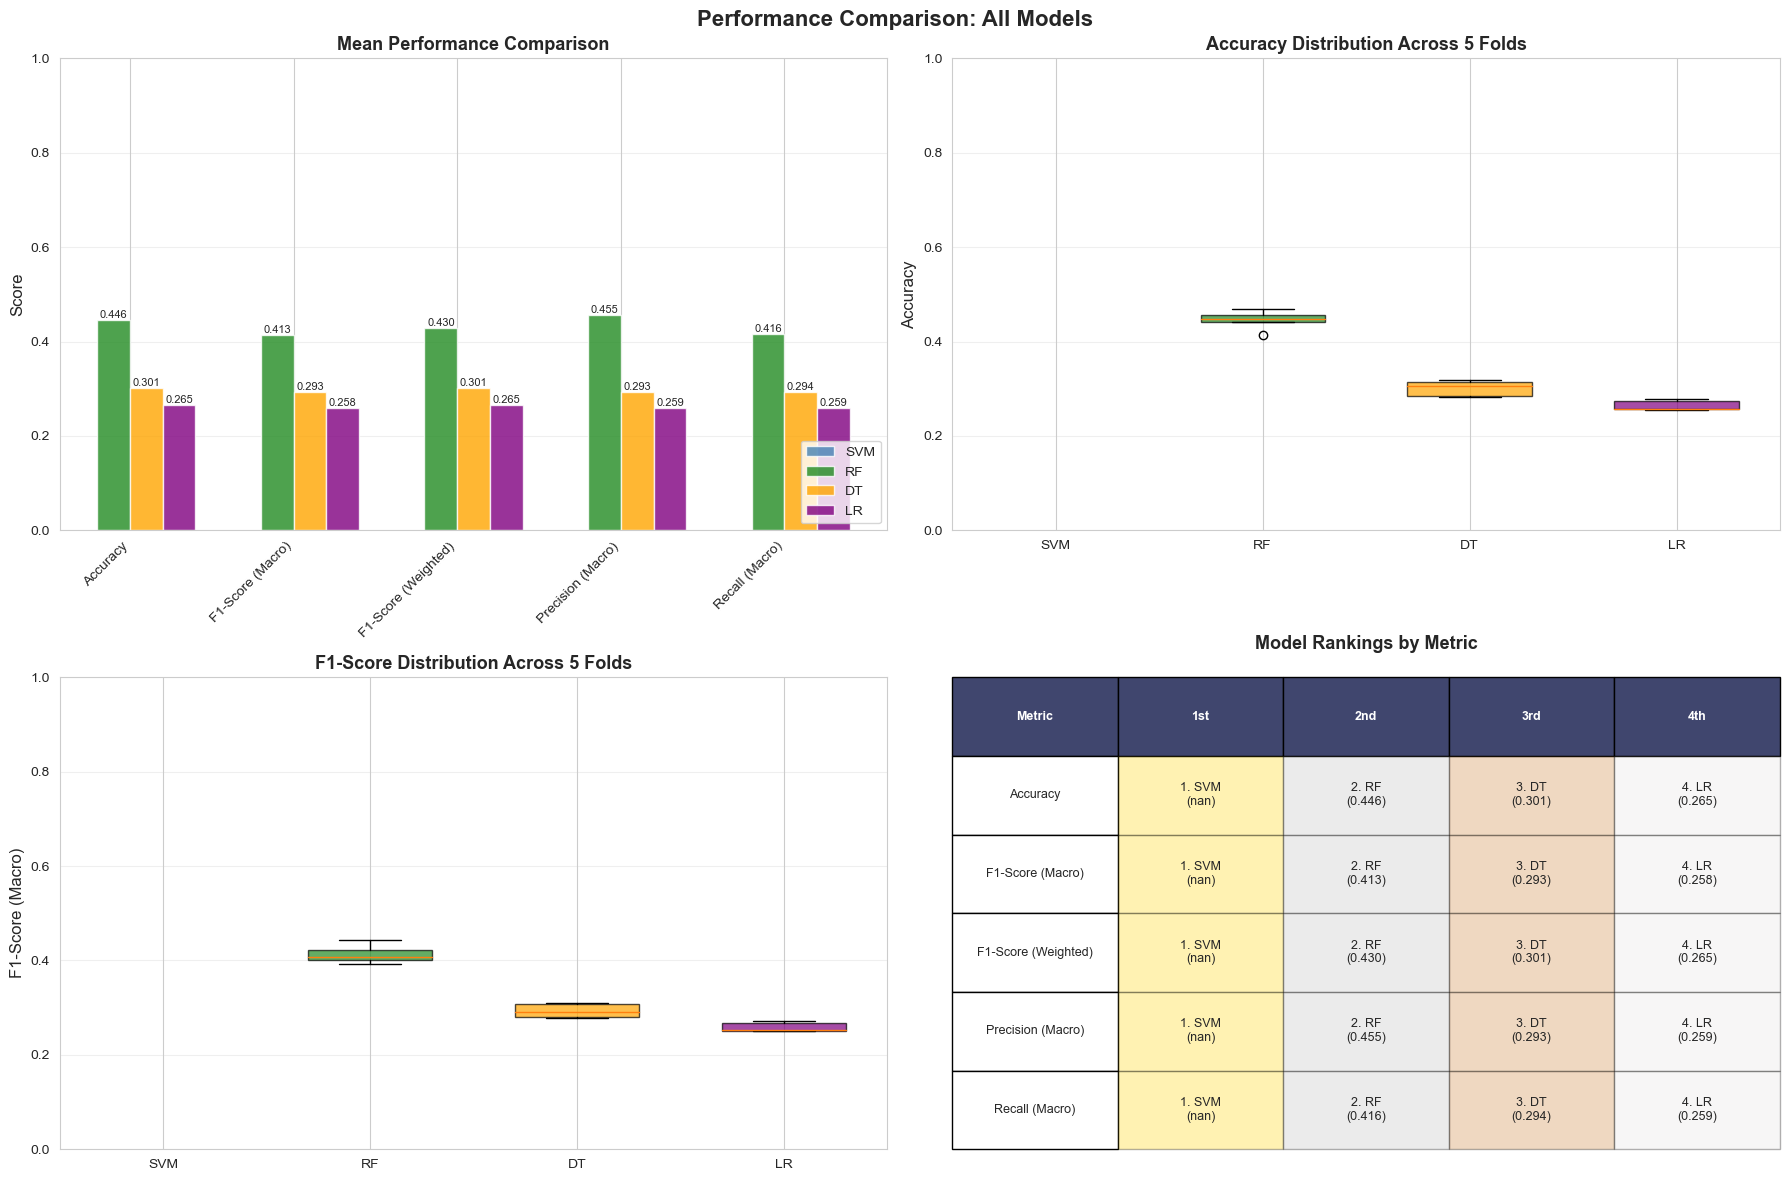


BEST MODEL BY METRIC

Accuracy:
  🥇 Best:  SVM                  = nan
  🥈 2nd:   Random Forest        = 0.4457
  🥉 3rd:   Decision Tree        = 0.3012
  4th:      SVM                  = nan
  Gap (Best-Worst): nan

F1-Score (Macro):
  🥇 Best:  SVM                  = nan
  🥈 2nd:   Random Forest        = 0.4129
  🥉 3rd:   Decision Tree        = 0.2933
  4th:      SVM                  = nan
  Gap (Best-Worst): nan

F1-Score (Weighted):
  🥇 Best:  SVM                  = nan
  🥈 2nd:   Random Forest        = 0.4297
  🥉 3rd:   Decision Tree        = 0.3007
  4th:      SVM                  = nan
  Gap (Best-Worst): nan

Precision (Macro):
  🥇 Best:  SVM                  = nan
  🥈 2nd:   Random Forest        = 0.4553
  🥉 3rd:   Decision Tree        = 0.2934
  4th:      SVM                  = nan
  Gap (Best-Worst): nan

Recall (Macro):
  🥇 Best:  SVM                  = nan
  🥈 2nd:   Random Forest        = 0.4160
  🥉 3rd:   Decision Tree        = 0.2937
  4th:      SVM                  = na

In [20]:
# Comprehensive comparison table for all models
all_models_comparison = {
    'Metric': ['Accuracy', 'F1-Score (Macro)', 'F1-Score (Weighted)', 'Precision (Macro)', 'Recall (Macro)'],
    'SVM Mean': [
        np.mean(fold_results['accuracy']),
        np.mean(fold_results['f1_macro']),
        np.mean(fold_results['f1_weighted']),
        np.mean(fold_results['precision_macro']),
        np.mean(fold_results['recall_macro'])
    ],
    'SVM Std': [
        np.std(fold_results['accuracy']),
        np.std(fold_results['f1_macro']),
        np.std(fold_results['f1_weighted']),
        np.std(fold_results['precision_macro']),
        np.std(fold_results['recall_macro'])
    ],
    'RF Mean': [
        np.mean(rf_fold_results['accuracy']),
        np.mean(rf_fold_results['f1_macro']),
        np.mean(rf_fold_results['f1_weighted']),
        np.mean(rf_fold_results['precision_macro']),
        np.mean(rf_fold_results['recall_macro'])
    ],
    'RF Std': [
        np.std(rf_fold_results['accuracy']),
        np.std(rf_fold_results['f1_macro']),
        np.std(rf_fold_results['f1_weighted']),
        np.std(rf_fold_results['precision_macro']),
        np.std(rf_fold_results['recall_macro'])
    ],
    'DT Mean': [
        np.mean(dt_fold_results['accuracy']),
        np.mean(dt_fold_results['f1_macro']),
        np.mean(dt_fold_results['f1_weighted']),
        np.mean(dt_fold_results['precision_macro']),
        np.mean(dt_fold_results['recall_macro'])
    ],
    'DT Std': [
        np.std(dt_fold_results['accuracy']),
        np.std(dt_fold_results['f1_macro']),
        np.std(dt_fold_results['f1_weighted']),
        np.std(dt_fold_results['precision_macro']),
        np.std(dt_fold_results['recall_macro'])
    ],
    'LR Mean': [
        np.mean(lr_fold_results['accuracy']),
        np.mean(lr_fold_results['f1_macro']),
        np.mean(lr_fold_results['f1_weighted']),
        np.mean(lr_fold_results['precision_macro']),
        np.mean(lr_fold_results['recall_macro'])
    ],
    'LR Std': [
        np.std(lr_fold_results['accuracy']),
        np.std(lr_fold_results['f1_macro']),
        np.std(lr_fold_results['f1_weighted']),
        np.std(lr_fold_results['precision_macro']),
        np.std(lr_fold_results['recall_macro'])
    ]
}

df_all_comparison = pd.DataFrame(all_models_comparison)

print("\n" + "="*100)
print("ALL MODELS COMPARISON (SVM, Random Forest, Decision Tree, Logistic Regression)")
print("="*100)
print(df_all_comparison.to_string(index=False))
print("="*100)

# Visualization 1: Mean scores comparison
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('Performance Comparison: All Models', fontsize=16, fontweight='bold')

metrics = df_all_comparison['Metric']
x = np.arange(len(metrics))
width = 0.2

colors = ['steelblue', 'forestgreen', 'orange', 'purple']
model_names = ['SVM', 'RF', 'DT', 'LR']

# Plot 1: Mean Performance Comparison (Bar Chart)
ax = axes[0, 0]
for i, model in enumerate(model_names):
    offset = width * (i - 1.5)
    bars = ax.bar(x + offset, df_all_comparison[f'{model} Mean'], width, 
                   label=model, alpha=0.8, color=colors[i])
    
    # Add value labels
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=8)

ax.set_ylabel('Score', fontsize=12)
ax.set_title('Mean Performance Comparison', fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics, rotation=45, ha='right')
ax.legend(loc='lower right')
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1])

# Plot 2: Accuracy Box Plot Comparison
ax = axes[0, 1]
accuracy_data = [
    fold_results['accuracy'],
    rf_fold_results['accuracy'],
    dt_fold_results['accuracy'],
    lr_fold_results['accuracy']
]
bp = ax.boxplot(accuracy_data, labels=model_names, patch_artist=True, widths=0.6)

for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set(alpha=0.7)

ax.set_ylabel('Accuracy', fontsize=12)
ax.set_title('Accuracy Distribution Across 5 Folds', fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1])

# Plot 3: F1-Score (Macro) Box Plot Comparison
ax = axes[1, 0]
f1_data = [
    fold_results['f1_macro'],
    rf_fold_results['f1_macro'],
    dt_fold_results['f1_macro'],
    lr_fold_results['f1_macro']
]
bp = ax.boxplot(f1_data, labels=model_names, patch_artist=True, widths=0.6)

for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set(alpha=0.7)

ax.set_ylabel('F1-Score (Macro)', fontsize=12)
ax.set_title('F1-Score Distribution Across 5 Folds', fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0, 1])

# Plot 4: Ranking by Metric
ax = axes[1, 1]
ranking_data = []
for i, metric in enumerate(metrics):
    scores = {
        'SVM': df_all_comparison['SVM Mean'][i],
        'RF': df_all_comparison['RF Mean'][i],
        'DT': df_all_comparison['DT Mean'][i],
        'LR': df_all_comparison['LR Mean'][i]
    }
    sorted_models = sorted(scores.items(), key=lambda x: x[1], reverse=True)
    ranking_data.append([m[0] for m in sorted_models])

# Create ranking table visualization
table_data = []
for i, metric in enumerate(metrics):
    row = [metric]
    for rank in range(4):
        model = ranking_data[i][rank]
        score = df_all_comparison[f'{model} Mean'][i]
        row.append(f"{rank+1}. {model}\n({score:.3f})")
    table_data.append(row)

ax.axis('tight')
ax.axis('off')
table = ax.table(cellText=table_data, 
                 colLabels=['Metric', '1st', '2nd', '3rd', '4th'],
                 cellLoc='center',
                 loc='center',
                 bbox=[0, 0, 1, 1])
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 2)

# Color header
for i in range(5):
    table[(0, i)].set_facecolor('#40466e')
    table[(0, i)].set_text_props(weight='bold', color='white')

# Color rankings
rank_colors = ['#FFD700', '#C0C0C0', '#CD7F32', '#E5E4E2']
for i in range(1, 6):
    for j in range(1, 5):
        table[(i, j)].set_facecolor(rank_colors[j-1])
        table[(i, j)].set_alpha(0.3)

ax.set_title('Model Rankings by Metric', fontsize=13, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

# Print detailed winner analysis
print("\n" + "="*100)
print("BEST MODEL BY METRIC")
print("="*100)
for i, metric in enumerate(metrics):
    scores = {
        'SVM': df_all_comparison['SVM Mean'][i],
        'Random Forest': df_all_comparison['RF Mean'][i],
        'Decision Tree': df_all_comparison['DT Mean'][i],
        'Logistic Regression': df_all_comparison['LR Mean'][i]
    }
    best_model = max(scores.items(), key=lambda x: x[1])
    worst_model = min(scores.items(), key=lambda x: x[1])
    
    print(f"\n{metric}:")
    print(f"  🥇 Best:  {best_model[0]:20} = {best_model[1]:.4f}")
    print(f"  🥈 2nd:   {sorted(scores.items(), key=lambda x: x[1], reverse=True)[1][0]:20} = {sorted(scores.items(), key=lambda x: x[1], reverse=True)[1][1]:.4f}")
    print(f"  🥉 3rd:   {sorted(scores.items(), key=lambda x: x[1], reverse=True)[2][0]:20} = {sorted(scores.items(), key=lambda x: x[1], reverse=True)[2][1]:.4f}")
    print(f"  4th:      {worst_model[0]:20} = {worst_model[1]:.4f}")
    print(f"  Gap (Best-Worst): {best_model[1] - worst_model[1]:.4f}")

print("="*100)

## 12. Save All Results to CSV

In [ ]:
# Save SVM results
df_summary.to_csv('svm_results_summary.csv', index=False)
print("✅ SVM Summary saved to: svm_results_summary.csv")

svm_fold_details = pd.DataFrame({
    'Fold': range(1, n_splits + 1),
    'Accuracy': fold_results['accuracy'],
    'F1_Macro': fold_results['f1_macro'],
    'F1_Weighted': fold_results['f1_weighted'],
    'Precision_Macro': fold_results['precision_macro'],
    'Recall_Macro': fold_results['recall_macro']
})
svm_fold_details.to_csv('svm_fold_details.csv', index=False)
print("✅ SVM Fold details saved to: svm_fold_details.csv")

df_svm_cm = pd.DataFrame(avg_cm, index=class_names, columns=class_names)
df_svm_cm.to_csv('svm_confusion_matrix.csv')
print("✅ SVM Confusion matrix saved to: svm_confusion_matrix.csv")

# Save Random Forest results
df_rf_summary.to_csv('rf_results_summary.csv', index=False)
print("\n✅ Random Forest Summary saved to: rf_results_summary.csv")

rf_fold_details = pd.DataFrame({
    'Fold': range(1, n_splits + 1),
    'Accuracy': rf_fold_results['accuracy'],
    'F1_Macro': rf_fold_results['f1_macro'],
    'F1_Weighted': rf_fold_results['f1_weighted'],
    'Precision_Macro': rf_fold_results['precision_macro'],
    'Recall_Macro': rf_fold_results['recall_macro']
})
rf_fold_details.to_csv('rf_fold_details.csv', index=False)
print("✅ Random Forest Fold details saved to: rf_fold_details.csv")

df_rf_cm = pd.DataFrame(rf_avg_cm, index=class_names, columns=class_names)
df_rf_cm.to_csv('rf_confusion_matrix.csv')
print("✅ Random Forest Confusion matrix saved to: rf_confusion_matrix.csv")

# Save Decision Tree results
dt_results_summary = {
    'Metric': ['Accuracy', 'F1-Score (Macro)', 'F1-Score (Weighted)', 'Precision (Macro)', 'Recall (Macro)'],
    'Mean': [
        np.mean(dt_fold_results['accuracy']),
        np.mean(dt_fold_results['f1_macro']),
        np.mean(dt_fold_results['f1_weighted']),
        np.mean(dt_fold_results['precision_macro']),
        np.mean(dt_fold_results['recall_macro'])
    ],
    'Std': [
        np.std(dt_fold_results['accuracy']),
        np.std(dt_fold_results['f1_macro']),
        np.std(dt_fold_results['f1_weighted']),
        np.std(dt_fold_results['precision_macro']),
        np.std(dt_fold_results['recall_macro'])
    ]
}
df_dt_summary = pd.DataFrame(dt_results_summary)
df_dt_summary.to_csv('dt_results_summary.csv', index=False)
print("\n✅ Decision Tree Summary saved to: dt_results_summary.csv")

dt_fold_details = pd.DataFrame({
    'Fold': range(1, n_splits + 1),
    'Accuracy': dt_fold_results['accuracy'],
    'F1_Macro': dt_fold_results['f1_macro'],
    'F1_Weighted': dt_fold_results['f1_weighted'],
    'Precision_Macro': dt_fold_results['precision_macro'],
    'Recall_Macro': dt_fold_results['recall_macro']
})
dt_fold_details.to_csv('dt_fold_details.csv', index=False)
print("✅ Decision Tree Fold details saved to: dt_fold_details.csv")

dt_avg_cm = np.mean(dt_fold_results['confusion_matrices'], axis=0)
df_dt_cm = pd.DataFrame(dt_avg_cm, index=class_names, columns=class_names)
df_dt_cm.to_csv('dt_confusion_matrix.csv')
print("✅ Decision Tree Confusion matrix saved to: dt_confusion_matrix.csv")

# Save Logistic Regression results
lr_results_summary = {
    'Metric': ['Accuracy', 'F1-Score (Macro)', 'F1-Score (Weighted)', 'Precision (Macro)', 'Recall (Macro)'],
    'Mean': [
        np.mean(lr_fold_results['accuracy']),
        np.mean(lr_fold_results['f1_macro']),
        np.mean(lr_fold_results['f1_weighted']),
        np.mean(lr_fold_results['precision_macro']),
        np.mean(lr_fold_results['recall_macro'])
    ],
    'Std': [
        np.std(lr_fold_results['accuracy']),
        np.std(lr_fold_results['f1_macro']),
        np.std(lr_fold_results['f1_weighted']),
        np.std(lr_fold_results['precision_macro']),
        np.std(lr_fold_results['recall_macro'])
    ]
}
df_lr_summary = pd.DataFrame(lr_results_summary)
df_lr_summary.to_csv('lr_results_summary.csv', index=False)
print("\n✅ Logistic Regression Summary saved to: lr_results_summary.csv")

lr_fold_details = pd.DataFrame({
    'Fold': range(1, n_splits + 1),
    'Accuracy': lr_fold_results['accuracy'],
    'F1_Macro': lr_fold_results['f1_macro'],
    'F1_Weighted': lr_fold_results['f1_weighted'],
    'Precision_Macro': lr_fold_results['precision_macro'],
    'Recall_Macro': lr_fold_results['recall_macro']
})
lr_fold_details.to_csv('lr_fold_details.csv', index=False)
print("✅ Logistic Regression Fold details saved to: lr_fold_details.csv")

lr_avg_cm = np.mean(lr_fold_results['confusion_matrices'], axis=0)
df_lr_cm = pd.DataFrame(lr_avg_cm, index=class_names, columns=class_names)
df_lr_cm.to_csv('lr_confusion_matrix.csv')
print("✅ Logistic Regression Confusion matrix saved to: lr_confusion_matrix.csv")

# Save comprehensive comparison
df_all_comparison.to_csv('all_models_comparison.csv', index=False)
print("\n✅ All Models Comparison saved to: all_models_comparison.csv")

print("\n" + "="*80)
print("ALL RESULTS SAVED SUCCESSFULLY!")
print("="*80)
print("\nSaved files:")
print("  SVM:")
print("    - svm_results_summary.csv")
print("    - svm_fold_details.csv")
print("    - svm_confusion_matrix.csv")
print("  Random Forest:")
print("    - rf_results_summary.csv")
print("    - rf_fold_details.csv")
print("    - rf_confusion_matrix.csv")
print("  Decision Tree:")
print("    - dt_results_summary.csv")
print("    - dt_fold_details.csv")
print("    - dt_confusion_matrix.csv")
print("  Logistic Regression:")
print("    - lr_results_summary.csv")
print("    - lr_fold_details.csv")
print("    - lr_confusion_matrix.csv")
print("  Comparison:")
print("    - all_models_comparison.csv")
print("="*80)

## 9. Compare SVM vs Random Forest

In [ ]:
# Comparison table
comparison_data = {
    'Metric': ['Accuracy', 'F1-Score (Macro)', 'F1-Score (Weighted)', 'Precision (Macro)', 'Recall (Macro)'],
    'SVM Mean': [
        np.mean(fold_results['accuracy']),
        np.mean(fold_results['f1_macro']),
        np.mean(fold_results['f1_weighted']),
        np.mean(fold_results['precision_macro']),
        np.mean(fold_results['recall_macro'])
    ],
    'SVM Std': [
        np.std(fold_results['accuracy']),
        np.std(fold_results['f1_macro']),
        np.std(fold_results['f1_weighted']),
        np.std(fold_results['precision_macro']),
        np.std(fold_results['recall_macro'])
    ],
    'RF Mean': [
        np.mean(rf_fold_results['accuracy']),
        np.mean(rf_fold_results['f1_macro']),
        np.mean(rf_fold_results['f1_weighted']),
        np.mean(rf_fold_results['precision_macro']),
        np.mean(rf_fold_results['recall_macro'])
    ],
    'RF Std': [
        np.std(rf_fold_results['accuracy']),
        np.std(rf_fold_results['f1_macro']),
        np.std(rf_fold_results['f1_weighted']),
        np.std(rf_fold_results['precision_macro']),
        np.std(rf_fold_results['recall_macro'])
    ]
}

df_comparison = pd.DataFrame(comparison_data)

print("\n" + "="*80)
print("SVM vs RANDOM FOREST COMPARISON")
print("="*80)
print(df_comparison.to_string(index=False))
print("="*80)

# Visualization: Side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Plot 1: Mean scores comparison
metrics = df_comparison['Metric']
x = np.arange(len(metrics))
width = 0.35

bars1 = axes[0].bar(x - width/2, df_comparison['SVM Mean'], width, 
                     label='SVM', alpha=0.8, color='steelblue')
bars2 = axes[0].bar(x + width/2, df_comparison['RF Mean'], width, 
                     label='Random Forest', alpha=0.8, color='forestgreen')

axes[0].set_ylabel('Score', fontsize=12)
axes[0].set_title('Mean Performance Comparison', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(metrics, rotation=45, ha='right')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim([0, 1])

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.3f}', ha='center', va='bottom', fontsize=9)

# Plot 2: Box plots comparison for accuracy across folds
data_to_plot = [fold_results['accuracy'], rf_fold_results['accuracy']]
bp = axes[1].boxplot(data_to_plot, labels=['SVM', 'Random Forest'],
                      patch_artist=True, widths=0.6)

# Color the boxes
bp['boxes'][0].set_facecolor('steelblue')
bp['boxes'][1].set_facecolor('forestgreen')

for box in bp['boxes']:
    box.set(alpha=0.7)

axes[1].set_ylabel('Accuracy', fontsize=12)
axes[1].set_title('Accuracy Distribution Across 5 Folds', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.show()

# Statistical comparison (which is better?)
print("\n" + "="*80)
print("WINNER BY METRIC")
print("="*80)
for i, metric in enumerate(metrics):
    svm_mean = df_comparison['SVM Mean'][i]
    rf_mean = df_comparison['RF Mean'][i]
    diff = abs(svm_mean - rf_mean)
    
    if svm_mean > rf_mean:
        winner = "SVM"
        better_score = svm_mean
    else:
        winner = "Random Forest"
        better_score = rf_mean
    
    print(f"{metric:25} → {winner:15} ({better_score:.4f}, +{diff:.4f})")
print("="*80)

## 10. Save All Results to CSV

In [ ]:
# Save SVM results
df_summary.to_csv('svm_results_summary.csv', index=False)
print("✅ SVM Summary saved to: svm_results_summary.csv")

svm_fold_details = pd.DataFrame({
    'Fold': range(1, n_splits + 1),
    'Accuracy': fold_results['accuracy'],
    'F1_Macro': fold_results['f1_macro'],
    'F1_Weighted': fold_results['f1_weighted'],
    'Precision_Macro': fold_results['precision_macro'],
    'Recall_Macro': fold_results['recall_macro']
})
svm_fold_details.to_csv('svm_fold_details.csv', index=False)
print("✅ SVM Fold details saved to: svm_fold_details.csv")

df_svm_cm = pd.DataFrame(avg_cm, index=class_names, columns=class_names)
df_svm_cm.to_csv('svm_confusion_matrix.csv')
print("✅ SVM Confusion matrix saved to: svm_confusion_matrix.csv")

# Save Random Forest results
df_rf_summary.to_csv('rf_results_summary.csv', index=False)
print("\n✅ Random Forest Summary saved to: rf_results_summary.csv")

rf_fold_details = pd.DataFrame({
    'Fold': range(1, n_splits + 1),
    'Accuracy': rf_fold_results['accuracy'],
    'F1_Macro': rf_fold_results['f1_macro'],
    'F1_Weighted': rf_fold_results['f1_weighted'],
    'Precision_Macro': rf_fold_results['precision_macro'],
    'Recall_Macro': rf_fold_results['recall_macro']
})
rf_fold_details.to_csv('rf_fold_details.csv', index=False)
print("✅ Random Forest Fold details saved to: rf_fold_details.csv")

df_rf_cm = pd.DataFrame(rf_avg_cm, index=class_names, columns=class_names)
df_rf_cm.to_csv('rf_confusion_matrix.csv')
print("✅ Random Forest Confusion matrix saved to: rf_confusion_matrix.csv")

# Save comparison
df_comparison.to_csv('svm_vs_rf_comparison.csv', index=False)
print("\n✅ SVM vs RF Comparison saved to: svm_vs_rf_comparison.csv")

print("\n" + "="*60)
print("All results saved successfully!")
print("="*60)
print("\nSaved files:")
print("  - svm_results_summary.csv")
print("  - svm_fold_details.csv")
print("  - svm_confusion_matrix.csv")
print("  - rf_results_summary.csv")
print("  - rf_fold_details.csv")
print("  - rf_confusion_matrix.csv")
print("  - svm_vs_rf_comparison.csv")
print("="*60)

## 6. Overall Performance Summary


5-FOLD CROSS-VALIDATION SUMMARY
             Metric     Mean      Std
           Accuracy 0.418601 0.008659
   F1-Score (Macro) 0.374100 0.015315
F1-Score (Weighted) 0.394007 0.013767
  Precision (Macro) 0.435578 0.010131
     Recall (Macro) 0.385120 0.011079


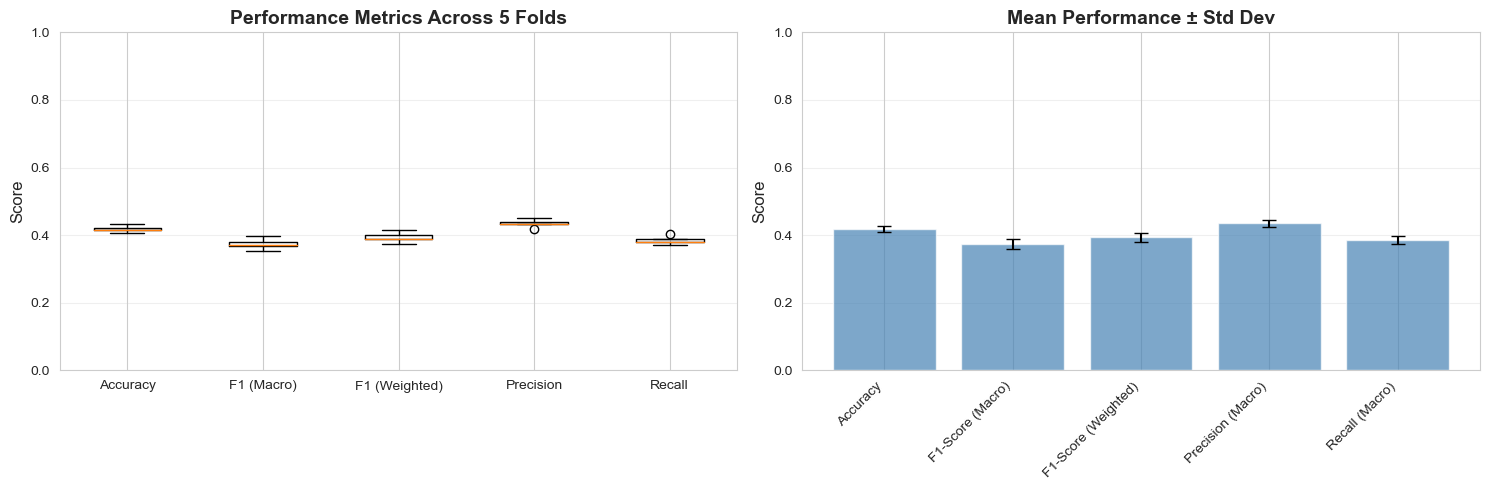

In [9]:
# Calculate mean and std for all metrics
results_summary = {
    'Metric': ['Accuracy', 'F1-Score (Macro)', 'F1-Score (Weighted)', 'Precision (Macro)', 'Recall (Macro)'],
    'Mean': [
        np.mean(fold_results['accuracy']),
        np.mean(fold_results['f1_macro']),
        np.mean(fold_results['f1_weighted']),
        np.mean(fold_results['precision_macro']),
        np.mean(fold_results['recall_macro'])
    ],
    'Std': [
        np.std(fold_results['accuracy']),
        np.std(fold_results['f1_macro']),
        np.std(fold_results['f1_weighted']),
        np.std(fold_results['precision_macro']),
        np.std(fold_results['recall_macro'])
    ]
}

df_summary = pd.DataFrame(results_summary)

print("\n" + "="*60)
print("5-FOLD CROSS-VALIDATION SUMMARY")
print("="*60)
print(df_summary.to_string(index=False))
print("="*60)

# Visualize results
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Box plot of metrics across folds
metrics_data = pd.DataFrame({
    'Accuracy': fold_results['accuracy'],
    'F1 (Macro)': fold_results['f1_macro'],
    'F1 (Weighted)': fold_results['f1_weighted'],
    'Precision': fold_results['precision_macro'],
    'Recall': fold_results['recall_macro']
})

axes[0].boxplot(metrics_data.values, labels=metrics_data.columns)
axes[0].set_ylabel('Score', fontsize=12)
axes[0].set_title('Performance Metrics Across 5 Folds', fontsize=14, fontweight='bold')
axes[0].grid(axis='y', alpha=0.3)
axes[0].set_ylim([0, 1])

# Plot 2: Bar plot with error bars
x_pos = np.arange(len(df_summary))
axes[1].bar(x_pos, df_summary['Mean'], yerr=df_summary['Std'], 
            capsize=5, alpha=0.7, color='steelblue')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(df_summary['Metric'], rotation=45, ha='right')
axes[1].set_ylabel('Score', fontsize=12)
axes[1].set_title('Mean Performance ± Std Dev', fontsize=14, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)
axes[1].set_ylim([0, 1])

plt.tight_layout()
plt.show()

## 7. Confusion Matrix Visualization

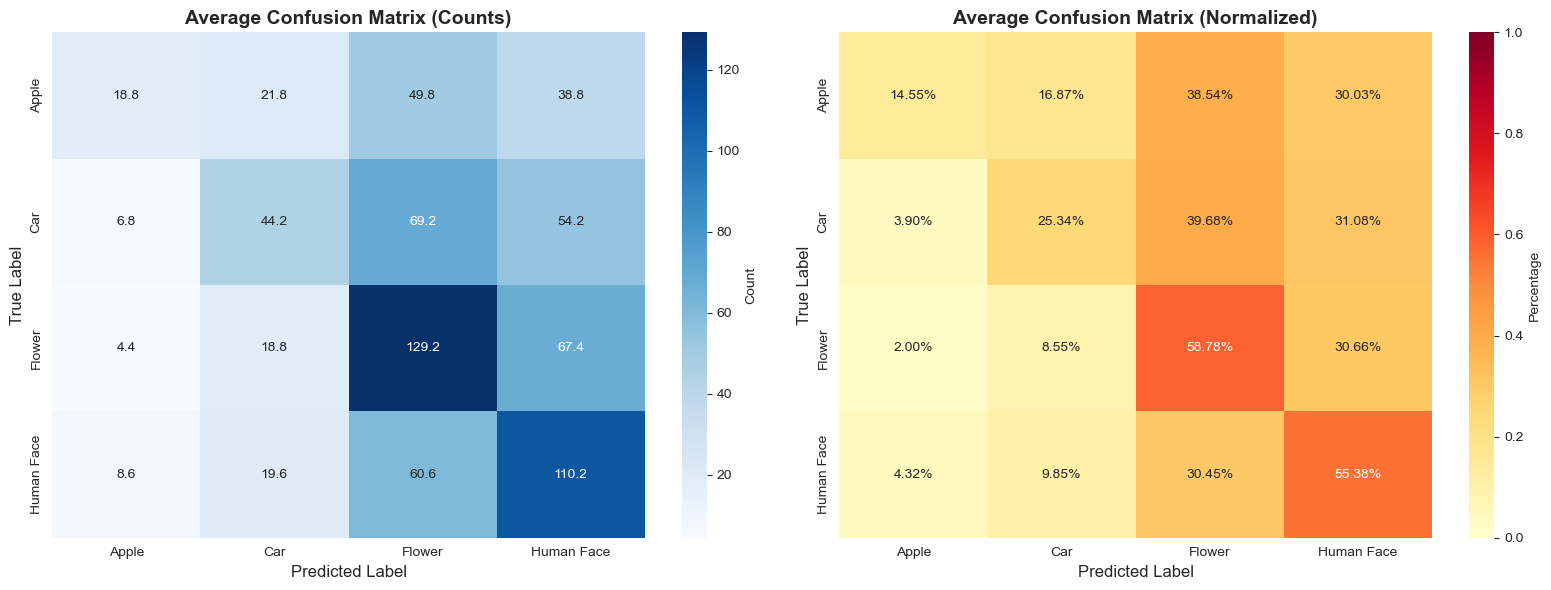


Per-Class Accuracy:
  Apple: 14.55%
  Car: 25.34%
  Flower: 58.78%
  Human Face: 55.38%


In [10]:
# Average confusion matrix across all folds
avg_cm = np.mean(fold_results['confusion_matrices'], axis=0)
avg_cm_normalized = avg_cm / avg_cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Raw counts
sns.heatmap(avg_cm, annot=True, fmt='.1f', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[0], cbar_kws={'label': 'Count'})
axes[0].set_title('Average Confusion Matrix (Counts)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Label', fontsize=12)
axes[0].set_xlabel('Predicted Label', fontsize=12)

# Plot 2: Normalized (percentages)
sns.heatmap(avg_cm_normalized, annot=True, fmt='.2%', cmap='YlOrRd', 
            xticklabels=class_names, yticklabels=class_names,
            ax=axes[1], cbar_kws={'label': 'Percentage'}, vmin=0, vmax=1)
axes[1].set_title('Average Confusion Matrix (Normalized)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('True Label', fontsize=12)
axes[1].set_xlabel('Predicted Label', fontsize=12)

plt.tight_layout()
plt.show()

# Per-class accuracy
print("\nPer-Class Accuracy:")
for i, class_name in enumerate(class_names):
    class_acc = avg_cm_normalized[i, i]
    print(f"  {class_name}: {class_acc:.2%}")

## 8. Save Results to CSV

In [ ]:
# Save summary results
df_summary.to_csv('svm_results_summary.csv', index=False)
print("✅ Summary saved to: svm_results_summary.csv")

# Save detailed fold results
fold_details = pd.DataFrame({
    'Fold': range(1, n_splits + 1),
    'Accuracy': fold_results['accuracy'],
    'F1_Macro': fold_results['f1_macro'],
    'F1_Weighted': fold_results['f1_weighted'],
    'Precision_Macro': fold_results['precision_macro'],
    'Recall_Macro': fold_results['recall_macro']
})
fold_details.to_csv('svm_fold_details.csv', index=False)
print("✅ Fold details saved to: svm_fold_details.csv")

# Save average confusion matrix
df_cm = pd.DataFrame(avg_cm, index=class_names, columns=class_names)
df_cm.to_csv('svm_confusion_matrix.csv')
print("✅ Confusion matrix saved to: svm_confusion_matrix.csv")

print("\n" + "="*60)
print("All results saved successfully!")
print("="*60)

✅ Summary saved to: svm_results_summary.csv
✅ Fold details saved to: svm_fold_details.csv
✅ Confusion matrix saved to: svm_confusion_matrix.csv

All results saved successfully!
